# mlogit de 3 regímenes con **cappeo** e impp_usa (1950–2023)

Notebook separada para no agrandar la notebook con cappeo. Usa exactamente el mismo cappeo (percentiles 5 y 95 en `impp_usa`, `E`, `ipc` y `pbird`), así que los modelos son comparables con los de `1950_2023_SSTVARS_impp_usa_capped.ipynb`.

Objetivo: verificar si, sin los trimestres extremos, la transición suave con 3 regímenes da una solución válida (como el VLSTAR con cappeo), y compararla con el TVAR de 3 regímenes con cappeo (umbrales 2,5% y 12,5%).

In [ ]:
source("preparar_dataframes.r")
source("src/sstvars_wrapper_v5.r")
source("src/erpt_historia_v35.R")

[1] "Se creó df_trimestral_crudo"
[1] "Se creó df_Arg"
[1] "Se creó df_ERPT_Arg1"
[1] "Se creó df_ERPT_Arg"
>>> sstvars_wrapper v4 cargado (Student, run_mlogit y estimación en tres etapas)


Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 


Attaching package: ‘sstvars’


The following object is masked from ‘package:tsDyn’:

    GIRF




>>> erpt_historia v28 cargada (velocidad del slider ajustable)



Attaching package: ‘plotly’


The following object is masked from ‘package:httr’:

    config


The following object is masked from ‘package:ggplot2’:

    last_plot


The following object is masked from ‘package:stats’:

    filter


The following object is masked from ‘package:graphics’:

    layout




## Cappeo (idéntico al de la notebook con cappeo)

In [2]:
cap_vars <- c("impp_usa", "E", "ipc", "pbird")

sds_antes <- sapply(df_ERPT_Arg[, cap_vars], sd, na.rm = TRUE)

df_ERPT_Arg_capped <- df_ERPT_Arg
limites <- list()
for (v in cap_vars) {
  lo <- quantile(df_ERPT_Arg[[v]], 0.05, na.rm = TRUE)
  hi <- quantile(df_ERPT_Arg[[v]], 0.95, na.rm = TRUE)
  df_ERPT_Arg_capped[[v]] <- pmin(pmax(df_ERPT_Arg[[v]], lo), hi)
  limites[[v]] <- c(p5 = unname(lo), p95 = unname(hi),
                    trimestres_acotados = sum(df_ERPT_Arg[[v]] < lo | df_ERPT_Arg[[v]] > hi, na.rm = TRUE))
}

sds_despues <- sapply(df_ERPT_Arg_capped[, cap_vars], sd, na.rm = TRUE)
cat("SD antes:\n"); print(sds_antes)
cat("SD después de cappear:\n"); print(sds_despues)
cat("\nLímites (diferencias logarítmicas) y trimestres acotados:\n"); print(round(do.call(rbind, limites), 4))
cat("\nInflación trimestral máxima después del cappeo (%):",
    round(100 * (exp(max(df_ERPT_Arg_capped$ipc)) - 1), 1), "\n")

SD antes:
  impp_usa          E        ipc      pbird 
0.02758807 0.23928824 0.19858620 0.02774553 
SD después de cappear:
  impp_usa          E        ipc      pbird 
0.01944584 0.15282085 0.12152850 0.02347437 

Límites (diferencias logarítmicas) y trimestres acotados:
              p5    p95 trimestres_acotados
impp_usa -0.0257 0.0512                  30
E        -0.0123 0.5111                  30
ipc      -0.0026 0.4431                  30
pbird    -0.0463 0.0428                  30

Inflación trimestral máxima después del cappeo (%): 55.8 


## mlogit, 3 regímenes, p = 2

Desvíos usados para escalar:
  impp_usa          E        ipc      pbird 
0.01944584 0.15282085 0.12152850 0.02347437 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating all the parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -2973.954

The largest loglik: -1073.088

PHASE 2: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -1387.902

The largest loglik: -1006.378

Filtering inappropriate estimates...

Filtered through 392 inappropriate  estimates with a larger log-likelihood

Calculating approximate standard errors...

Warning message in warn_eigens(ret, allow_unstab = allow_unstab):
“Regime 3 has near-unit-roots! Consider building a model from the next-largest local maximum with the function 'alt_stvar' by adjusting its argument 'which_largest' (or use the function 'filter_estimates').”
Finished!




========= Unstructured fitted model ==========


The log-likelihood of the supplied model:    -1163.496
Constrained log-likelihood prior estimation: -1175.984

The log-likelihood after robust estimation:  -1166.861

The log-likelihood after final estimation:   -1147.248

Calculating approximate standard errors...



========= Structured fitted model (heteroskedasticity) ==========
Saving trained models to models/ folder

 >>> DIAGNOSTIC PLOTS


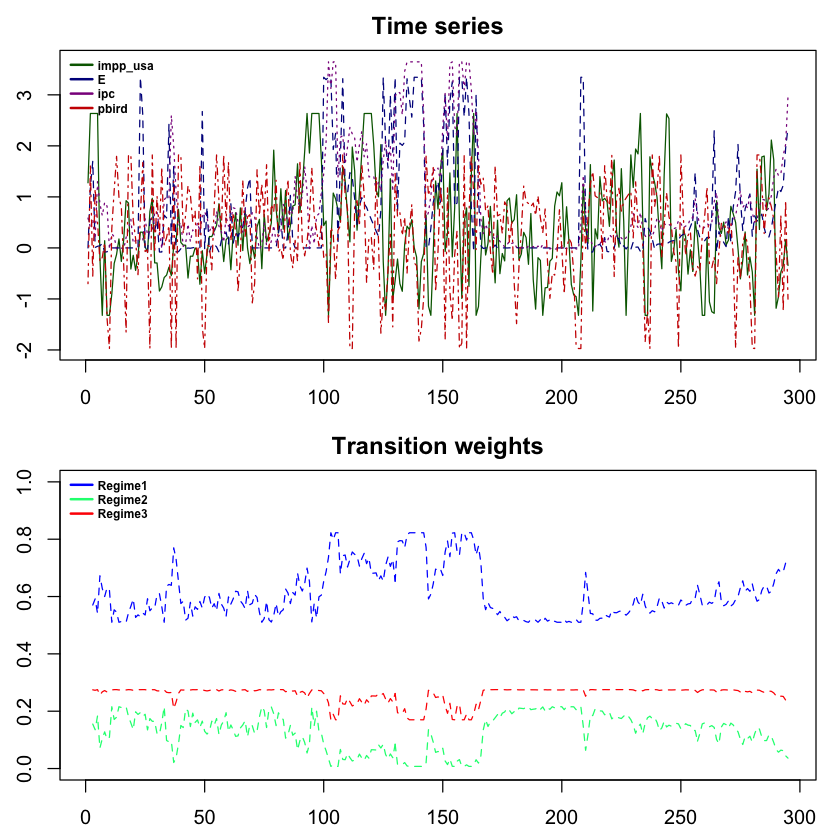

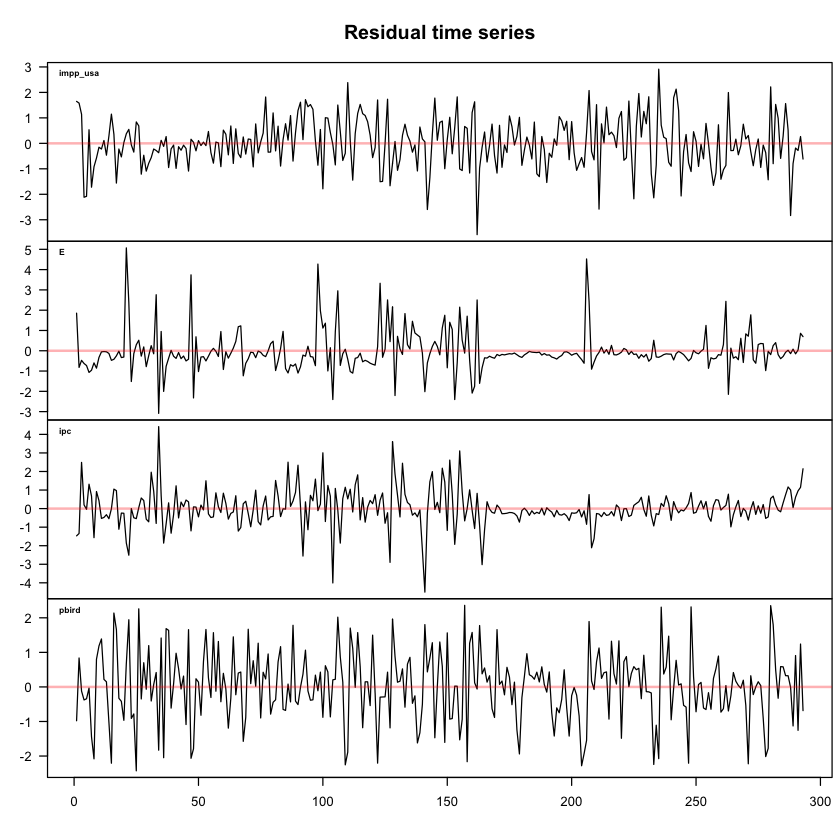

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



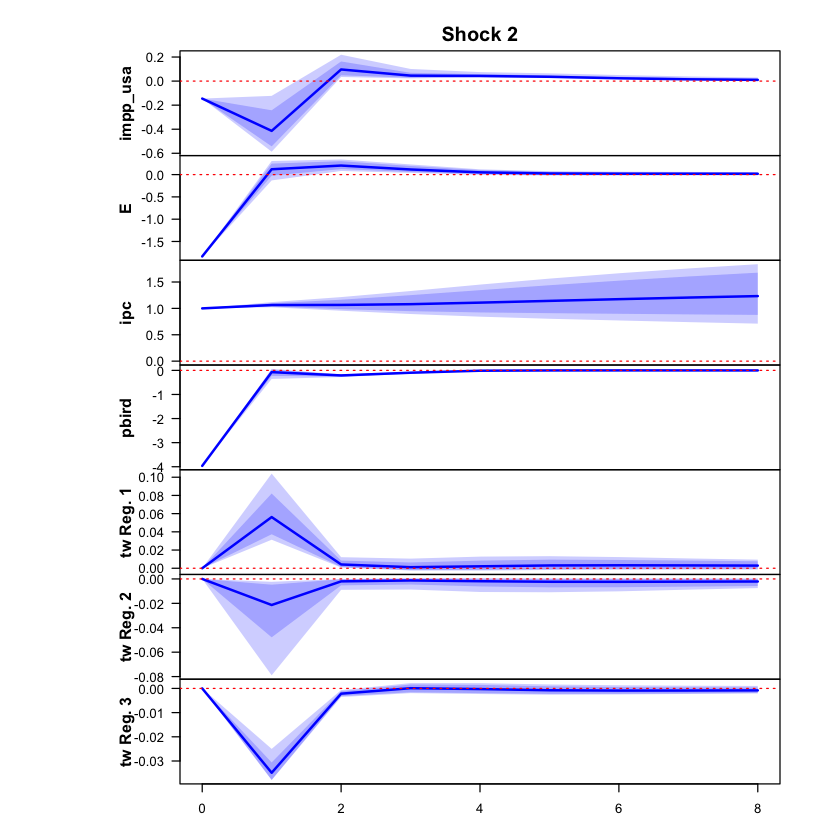

 >>> Linear IRF ( 1  shock units)


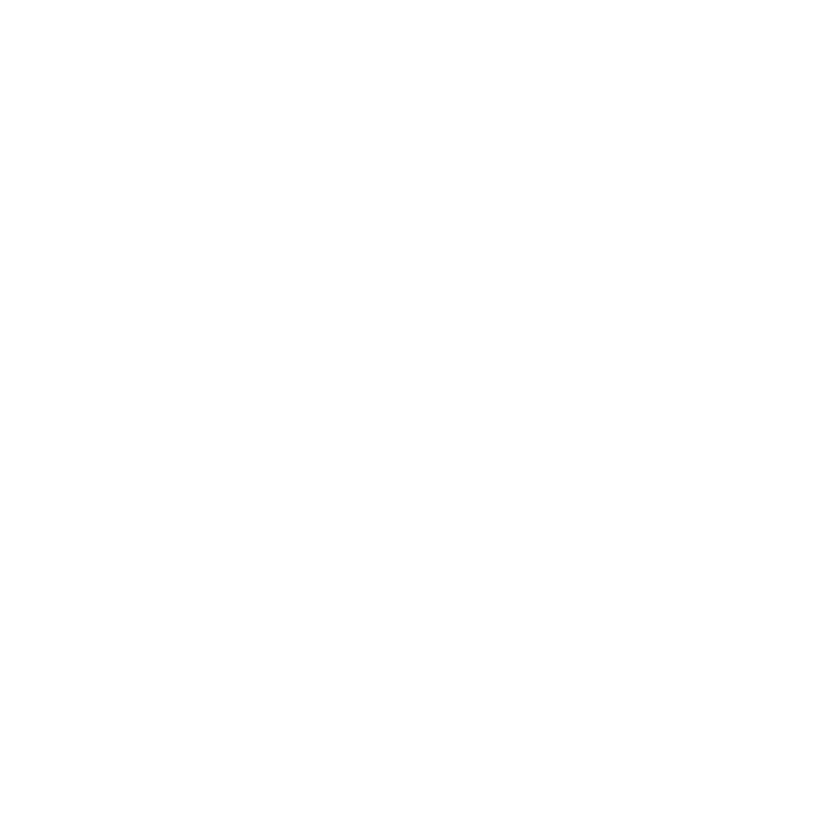

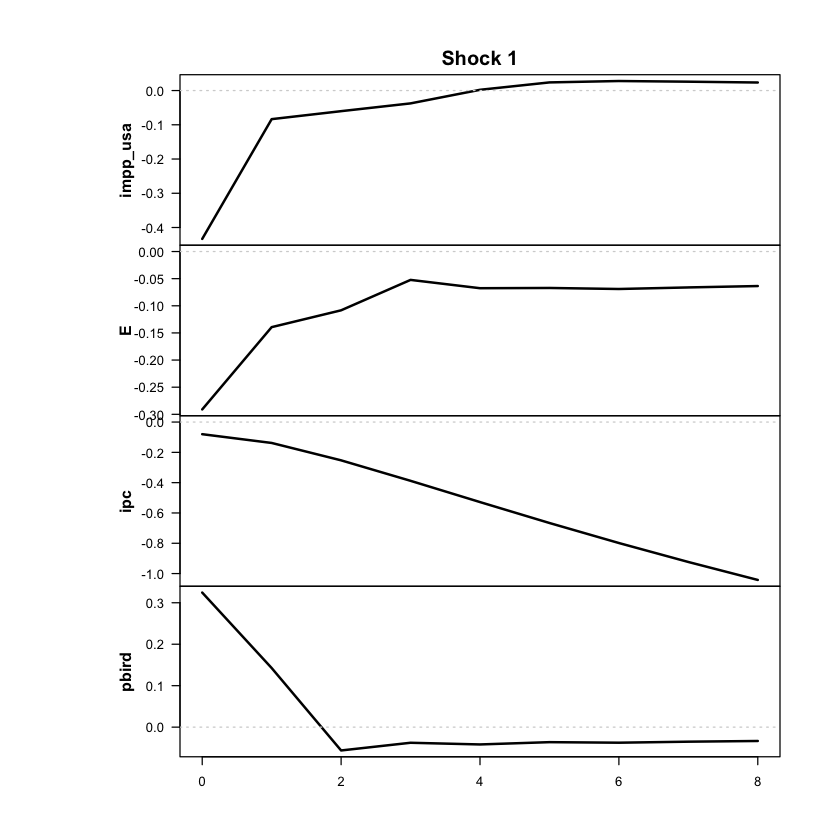

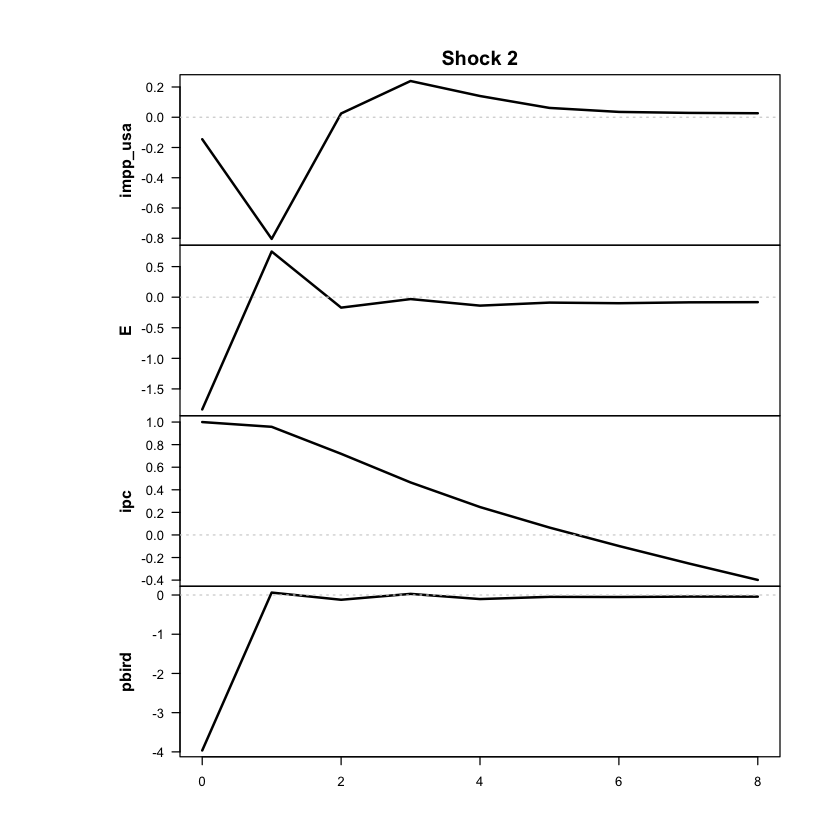

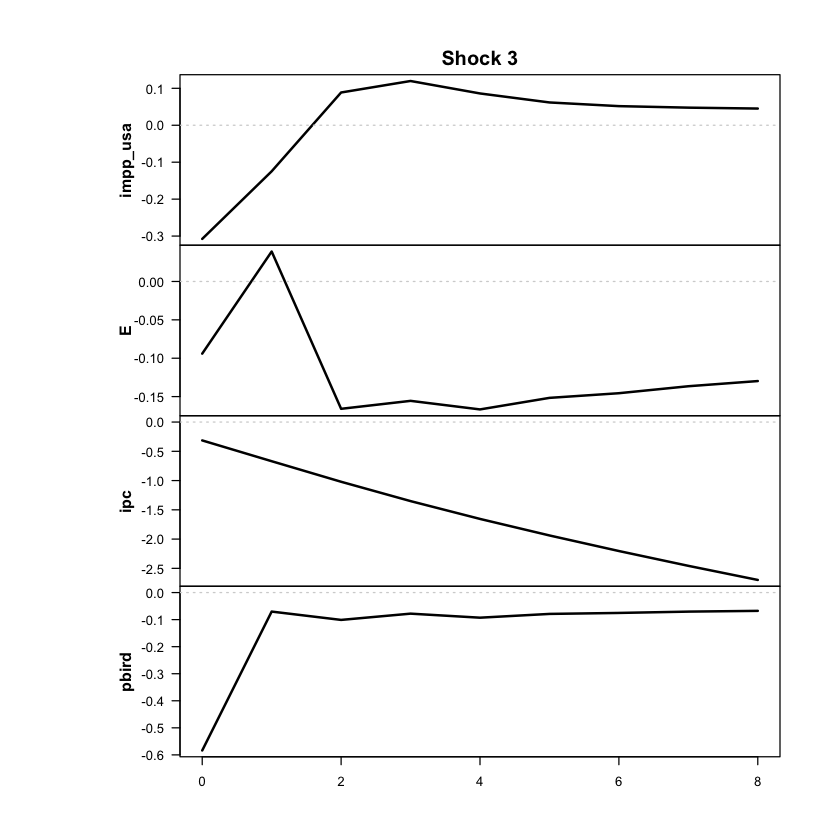

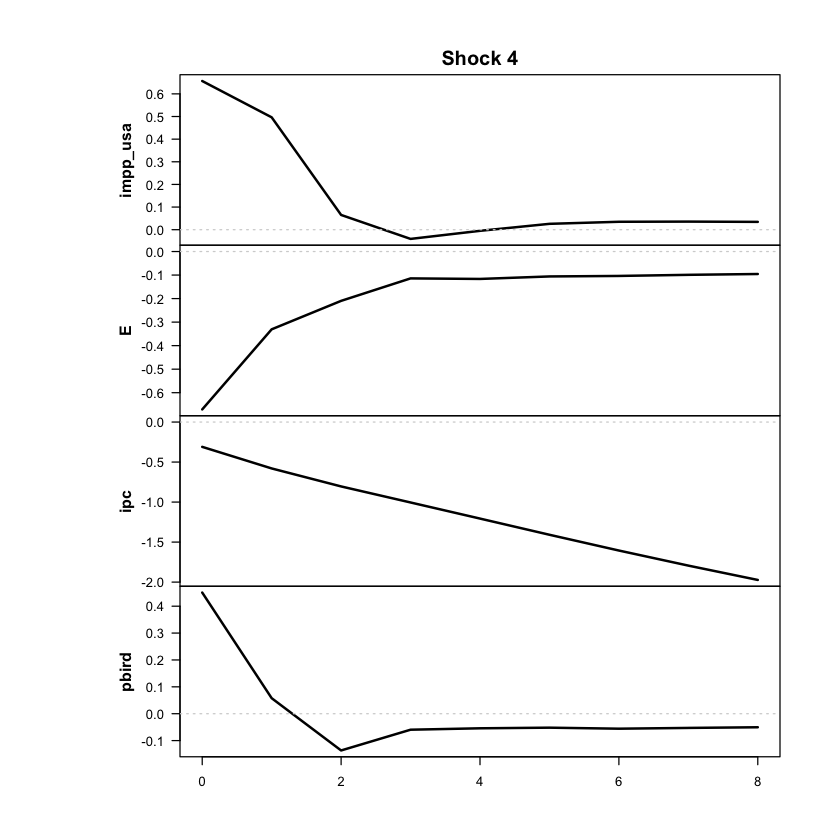

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



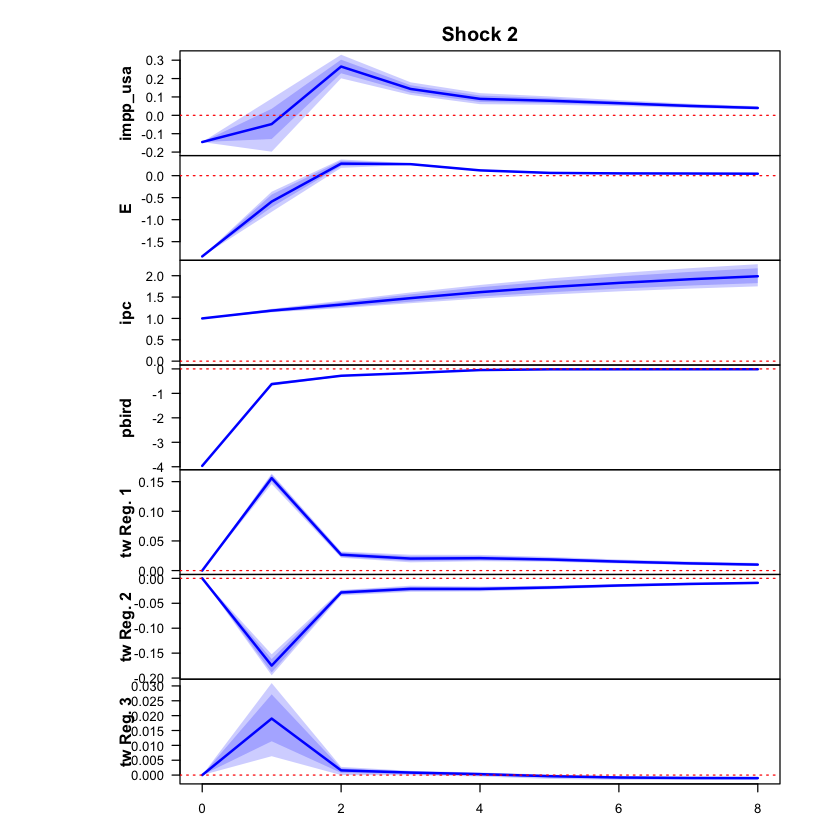

 >>> Linear IRF ( 1  shock units)


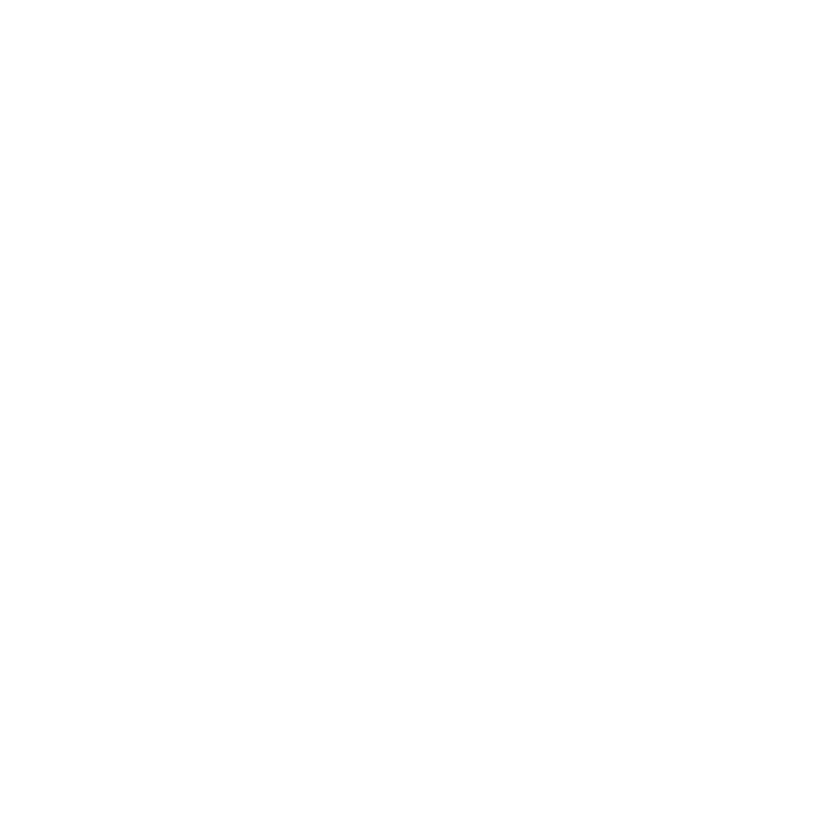

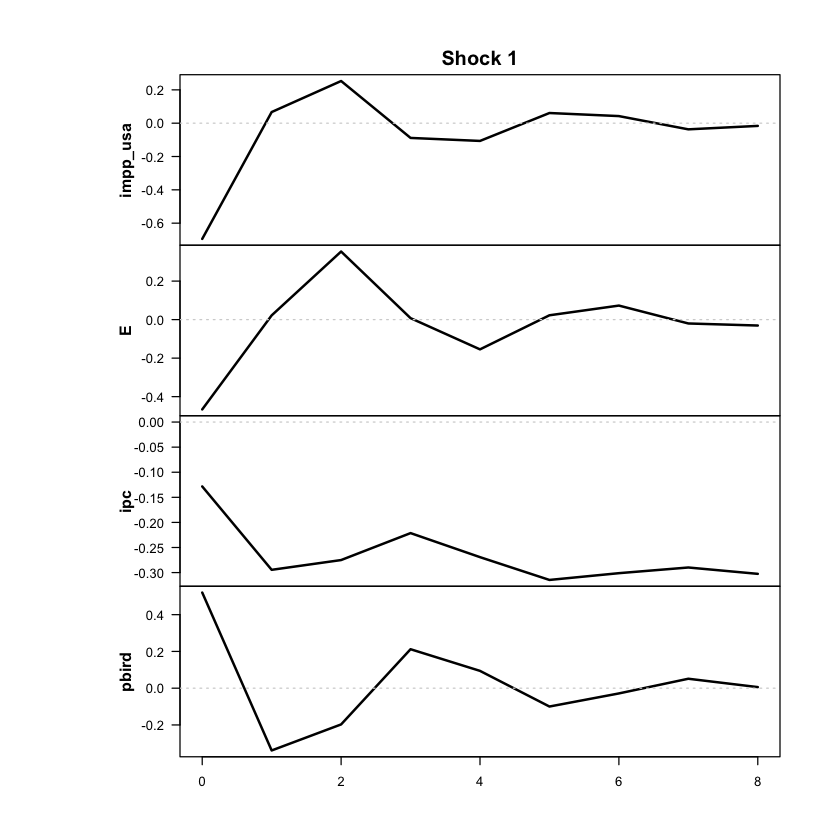

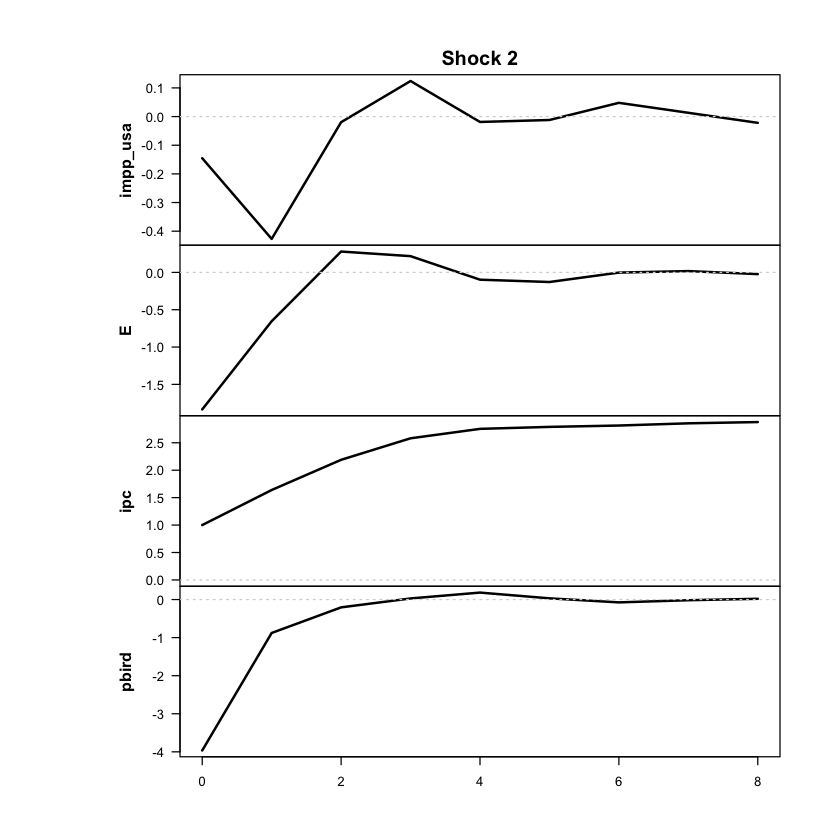

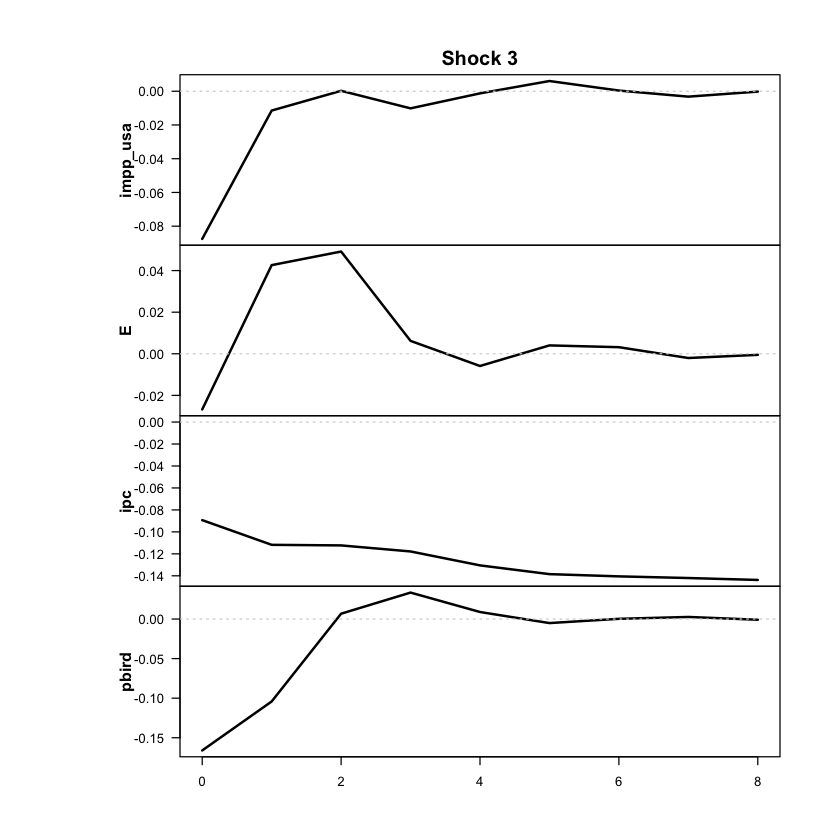

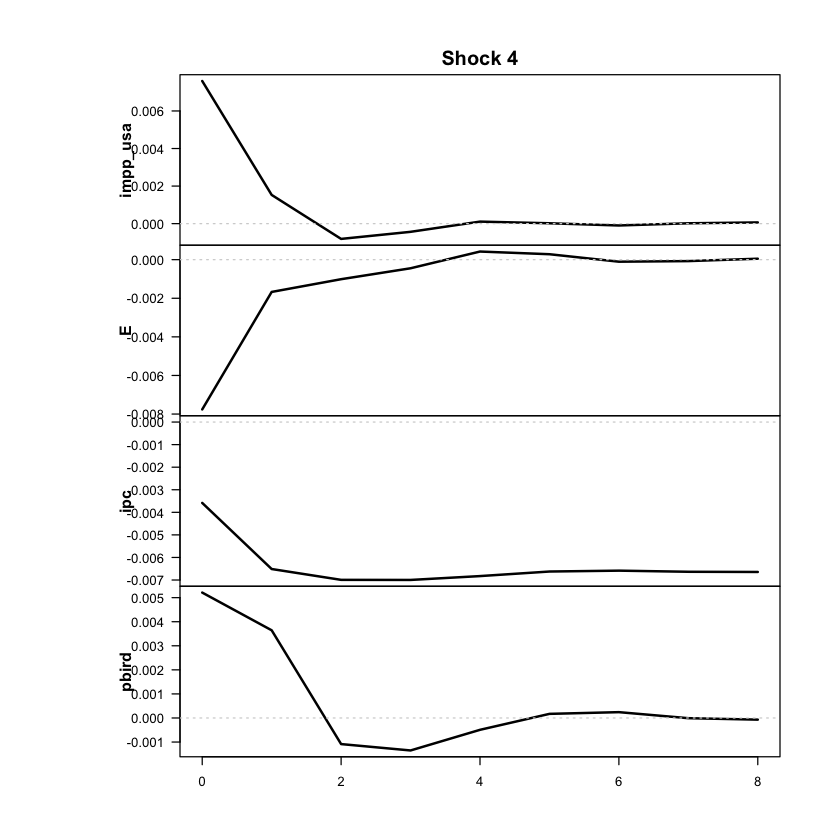

+++++++++ RÉGIMEN  3 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



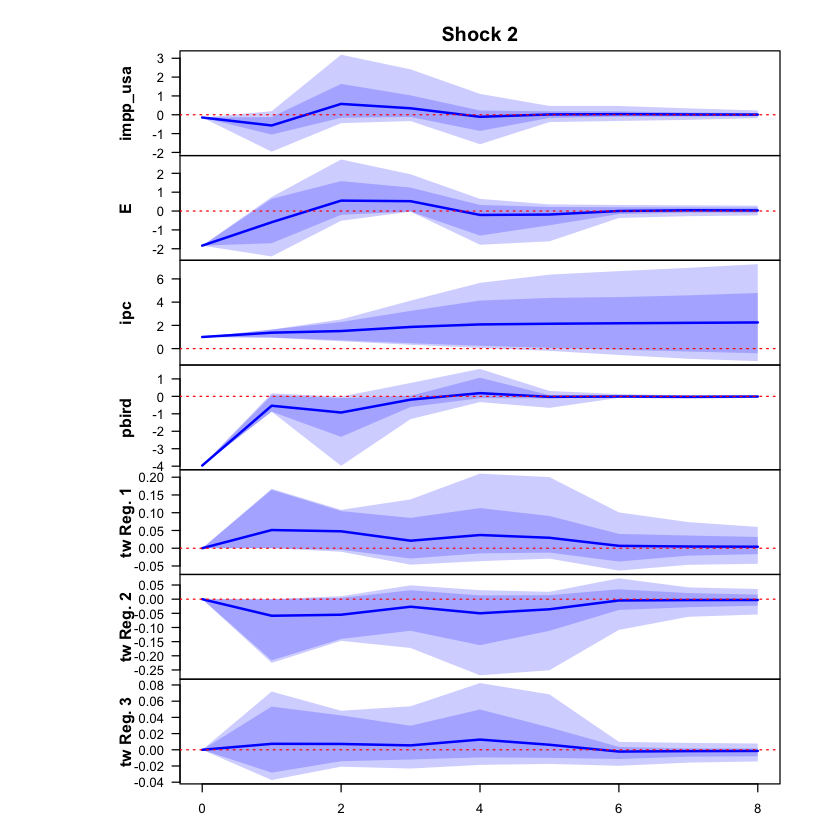

 >>> Linear IRF ( 1  shock units)


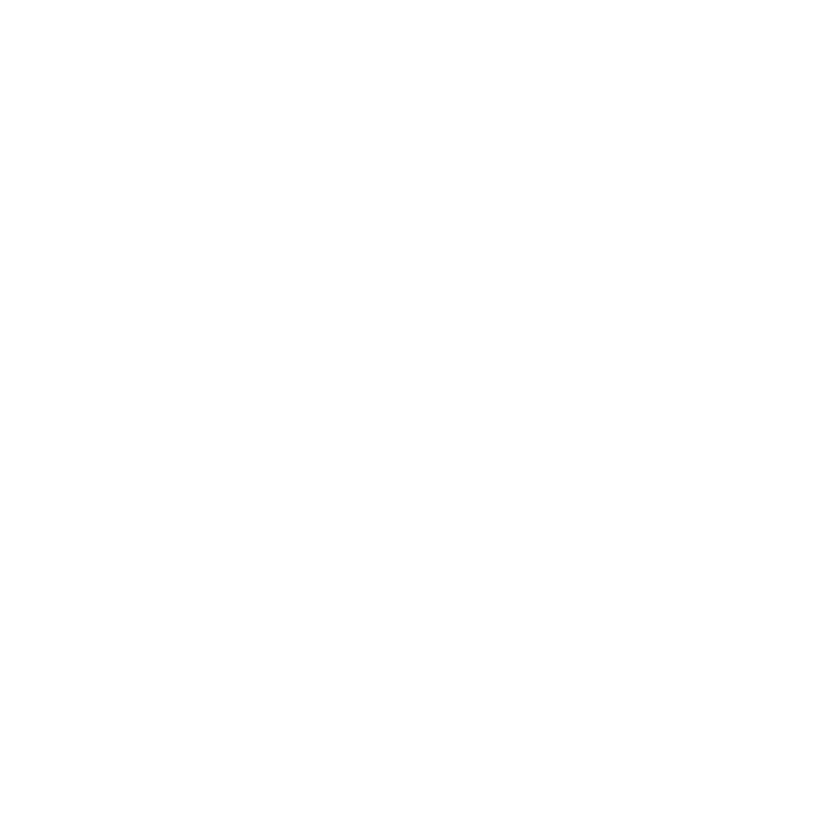

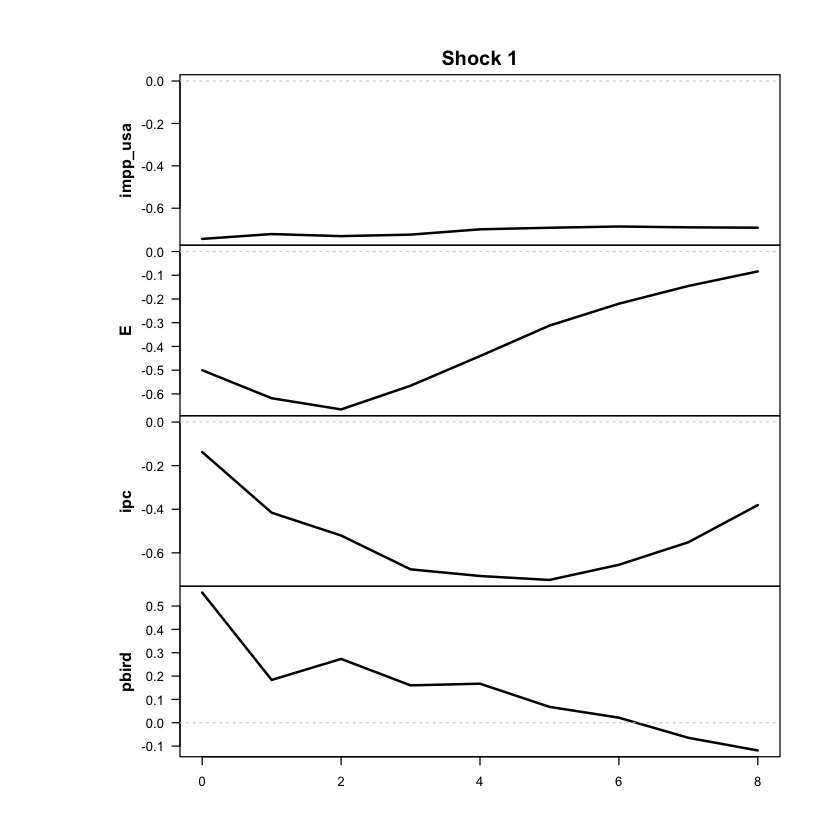

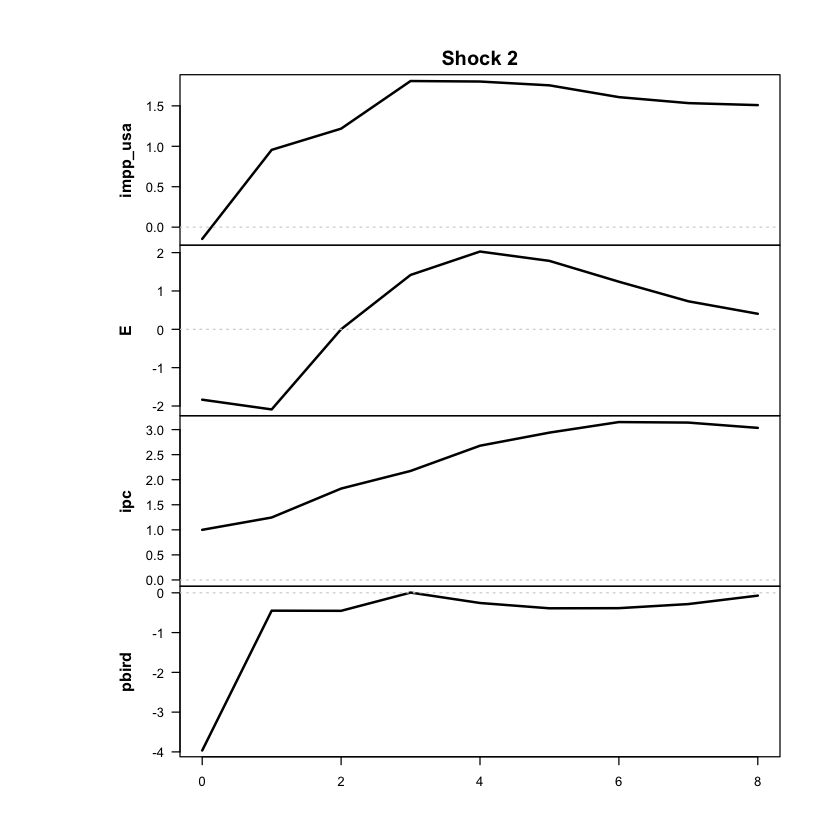

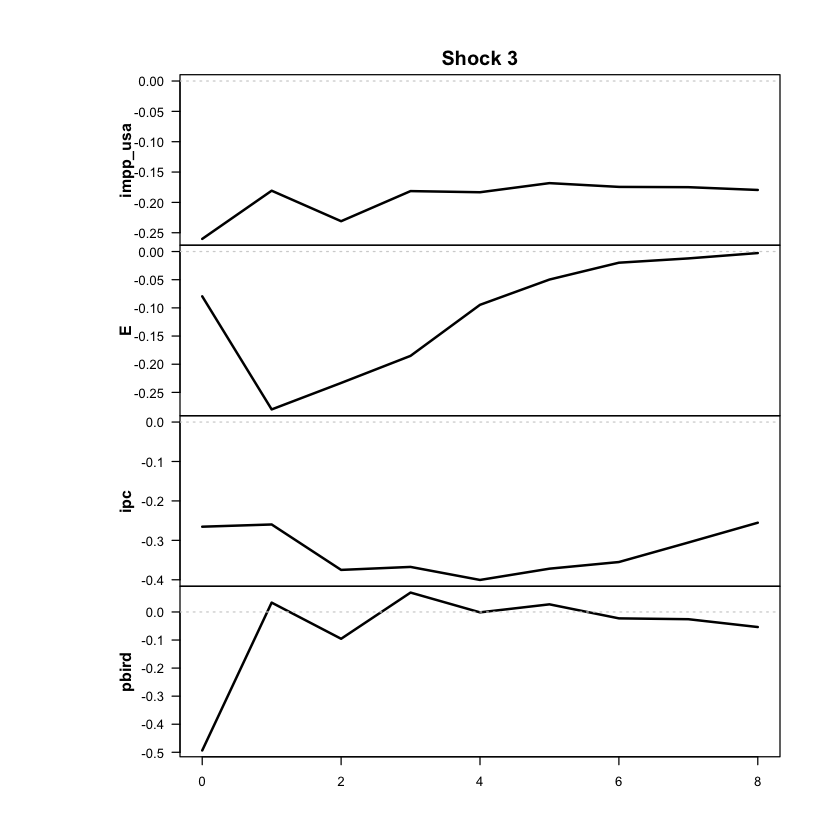

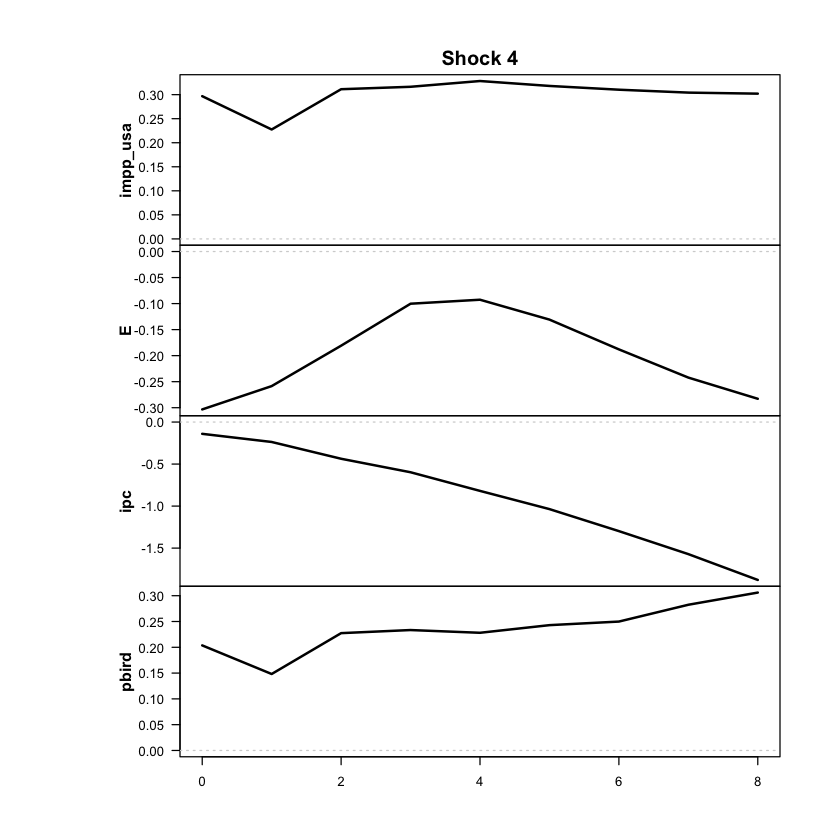

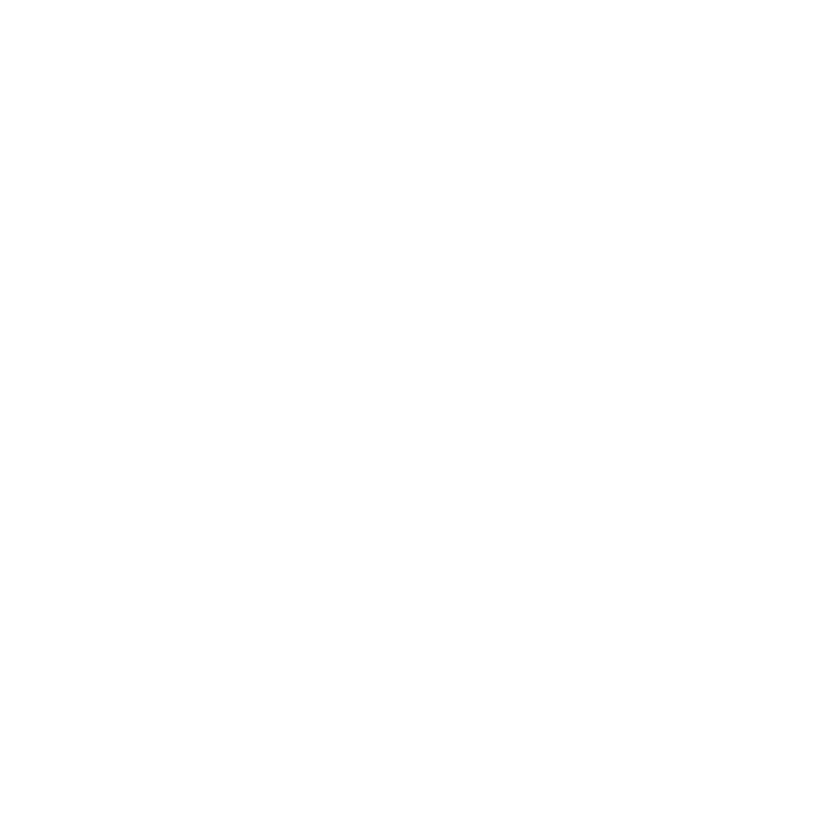

In [3]:
res <- run_mlogit(
  data = df_ERPT_Arg_capped,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral',
  feature_lag = 2,
  n_regimes = 3,
  cumulative = TRUE,
  thr_var = 'ipc',
  thr_lag = 1,
  shock_var = 'E',
  response_vars = c('ipc'),
  run_tests = FALSE,
  irf_horizons = NULL,
  irf_shocks = 1,
  diagnostic_plots = TRUE,
  nrounds = 500,
  load_presaved = FALSE
)

In [4]:
ic_mlogit3_p2_cap <- criterios_info(res, "MLOGIT 3 reg p=2 cap")
print(ic_mlogit3_p2_cap)

                modelo regimenes parametros  loglik  AIC     HQ    BIC
1 MLOGIT 3 reg p=2 cap         3        142 -1163.5 2611 2820.3 3133.6


In [5]:
resumen_modelo(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"))
# Mirar: dos cambios de régimen dominante, ordenados, y si se parecen a 2,5% y 12,5%.

Modelo: mlogit | regímenes: 3 | rezagos: 2 | errores: Gaussian 
Transición mlogit (parámetros gamma, escalados): 0.627, 0.26, -0.257, -0.786 
Cambios de régimen dominante según la inflación de t-1:
Trimestres por régimen (régimen de mayor peso): régimen 1 = 293 | régimen 2 = 0 | régimen 3 = 0 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2 Régimen 3
impp_usa      0.70       NaN       NaN
E            10.32       NaN       NaN
ipc          11.54       NaN       NaN
pbird         0.57       NaN       NaN


In [6]:
explorar_optimos(res, n = 20)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest   loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -1006.38              NA    NA         NA        80/171/42
             2 -1032.40              NA    NA         NA        196/72/25
             3 -1032.41              NA    NA         NA        61/74/158
             4 -1034.23              NA    NA         NA        72/202/19
             5 -1035.27              NA    NA         NA         8/72/213
             6 -1037.22              NA    NA         NA        187/59/47
             7 -1039.31              NA    NA         NA         219/0/74
             8 -1039.72              NA    NA         NA        149/81/63
          

In [7]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

mlogit Gaussian STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 2, M = 3, d = 4, #parameters = 142, #observations = 293 x 4
  Switching variables: ipc with 1 lag.

Regime 1 
Weight params: 0.71, 0.10 
Regime means:  0.81,  0.14,  0.35, -0.78

   Y      phi0          A1                                 A2                  
1 y1 = [  0.55 ] + [  0.35 -0.17 -0.32  0.15 ] y1.1 + [  0.07  0.17  0.15 -0.12
2 y2   [ -0.10 ]   [ -0.09  0.17  0.19 -0.17 ] y2.1   [  0.08  0.13  0.14  0.05
3 y3   [  0.02 ]   [  0.00  0.19  0.74  0.13 ] y3.1   [  0.12  0.13  0.10  0.01
4 y4   [ -0.49 ]   [ -0.16 -0.19  0.17  0.23 ] y4.1   [  0.00  0.19  0.07  0.09
             Omega                     1/2     
1 ] y1.2 + [  0.85 -0.21 -0.06  0.36 ]     eps1
2 ] y2.2   [ -0.21  0.57  0.16 -0.03 ]     eps2
3 ] y3.2   [ -0.06  0.16  0.17 -0.05 ]     eps3
4 ] y4.2   [  0.36 -0.03 -0.05  0.88 ]     eps4

Regime 2 
Weight params: -0.33, -0.79 
Regime means: -1.18,  0.86,  0.26,  1.58

   

In [8]:
shock_mlogit3_p2_cap <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_mlogit3_p2_cap <- 2
shock_mlogit3_p2_cap

Efecto de impacto de cada shock (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa -0.0084  0.0004 -0.0060  0.0128
  E        -0.0445  0.0434 -0.0144 -0.1026
  ipc      -0.0097 -0.0188 -0.0381 -0.0377
  pbird     0.0076  0.0144 -0.0137  0.0106

Participación de E en el efecto de cada shock:
shock_1 shock_2 shock_3 shock_4 
   0.47    0.41    0.13    0.62 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.219  -0.433   2.655   0.367 

>>> Shock sugerido como cambiario: 4 (confirmalo: debe mover mucho a E y poco a ipc )


Shock 4 
      4

### ERPT — mlogit p = 2 (solo si pasó el diagnóstico)

In [ ]:
out_impp_usa_mlogit3_p2_cap <- erpt_historia(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_mlogit3_p2_cap)

In [ ]:
out_impp_usa_mlogit3_p2_cap_acum <- erpt_historia(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_mlogit3_p2_cap,
                      definicion = "acumulado")

In [ ]:
graficar_transicion(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_mlogit3_p2_cap")

## mlogit, 3 regímenes, p = 3 (robustez: correr solo si p = 2 da una solución válida)

Desvíos usados para escalar:
  impp_usa          E        ipc      pbird 
0.01944584 0.15282085 0.12152850 0.02347437 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating all the parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -2444.5

The largest loglik: -1055.077

PHASE 2: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -2444.5

The largest loglik: -1006.949

Filtering inappropriate estimates...

Filtered through 136 inappropriate  estimates with a larger log-likelihood

Calculating approximate standard errors...

Warning message in warn_eigens(ret, allow_unstab = allow_unstab):
“Regime 3 has near-unit-roots! Consider building a model from the next-largest local maximum with the function 'alt_stvar' by adjusting its argument 'which_largest' (or use the function 'filter_estimates').”
Finished!




========= Unstructured fitted model ==========


The log-likelihood of the supplied model:    -1090.958
Constrained log-likelihood prior estimation: -1411.284

The log-likelihood after robust estimation:  -1213.867

The log-likelihood after final estimation:   -1213.867

Calculating approximate standard errors...



========= Structured fitted model (heteroskedasticity) ==========
Saving trained models to models/ folder

 >>> DIAGNOSTIC PLOTS


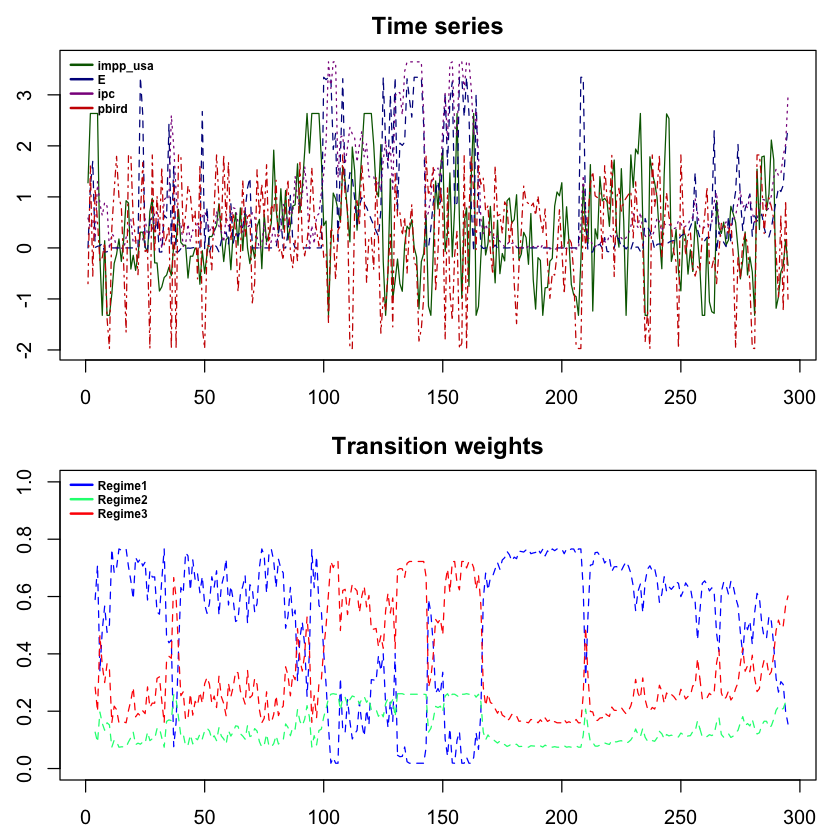

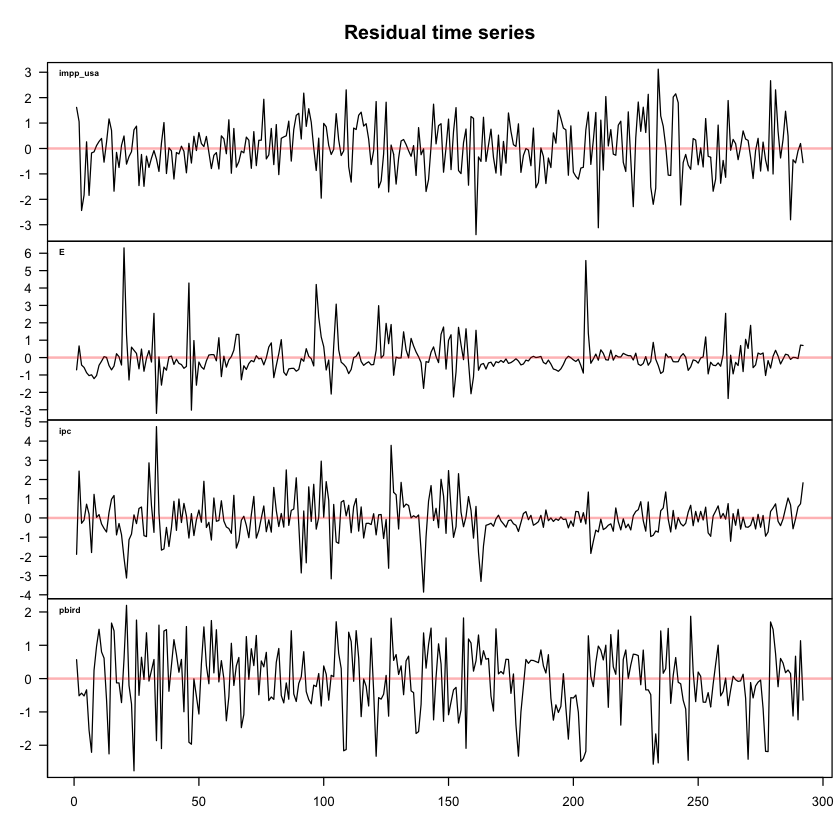

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



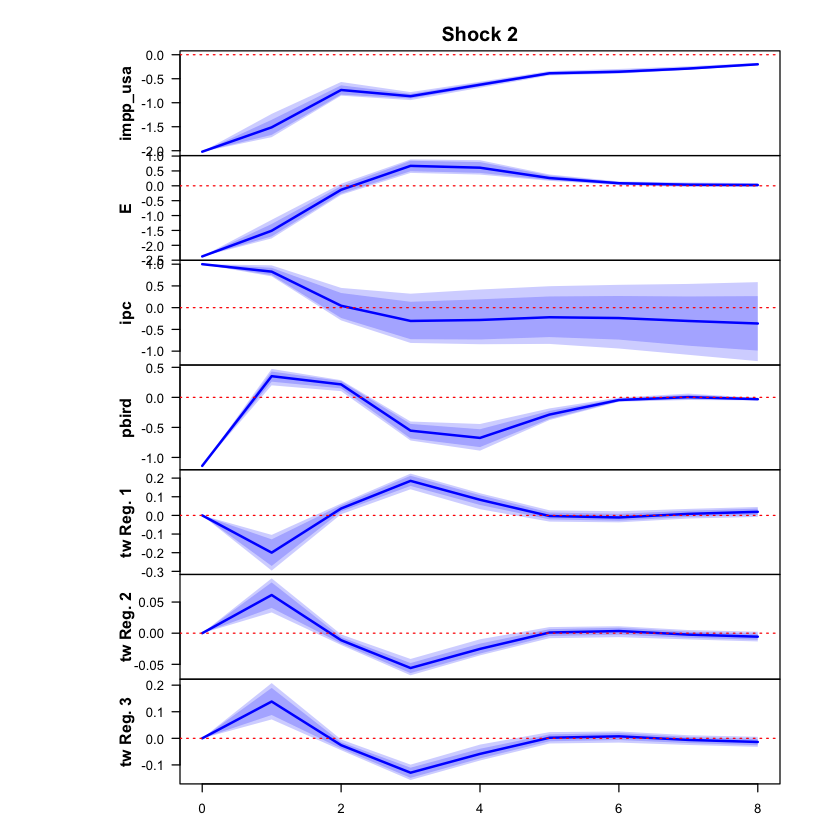

 >>> Linear IRF ( 1  shock units)


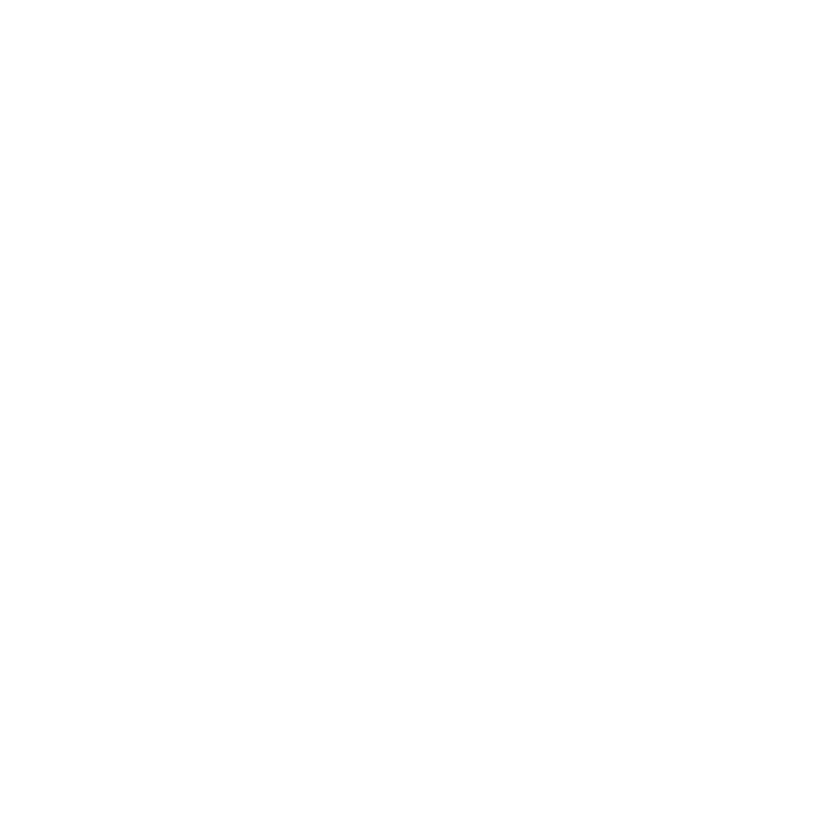

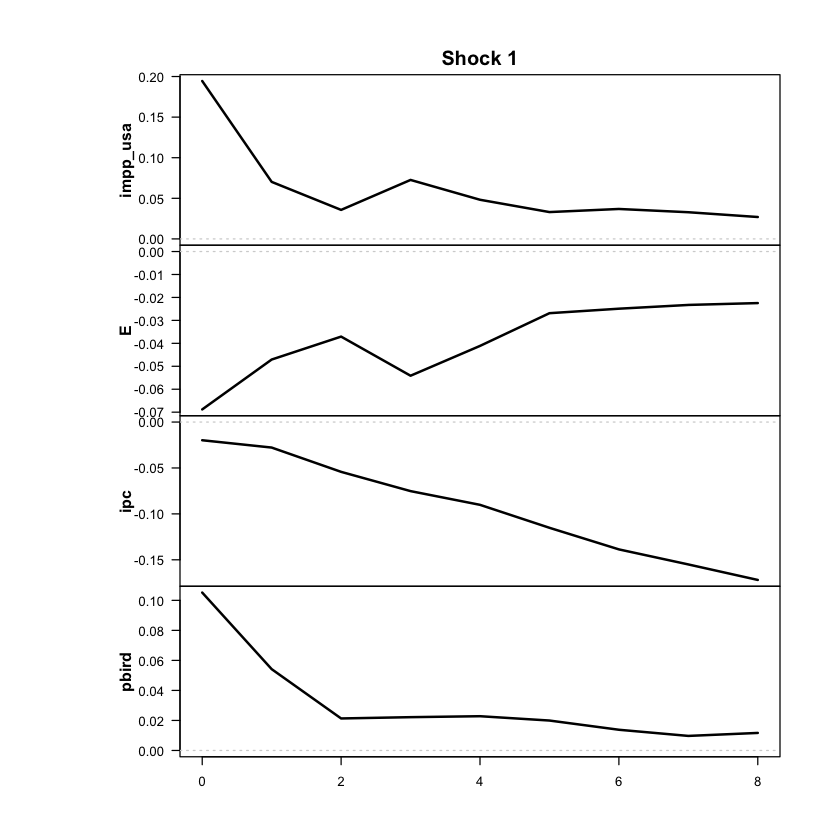

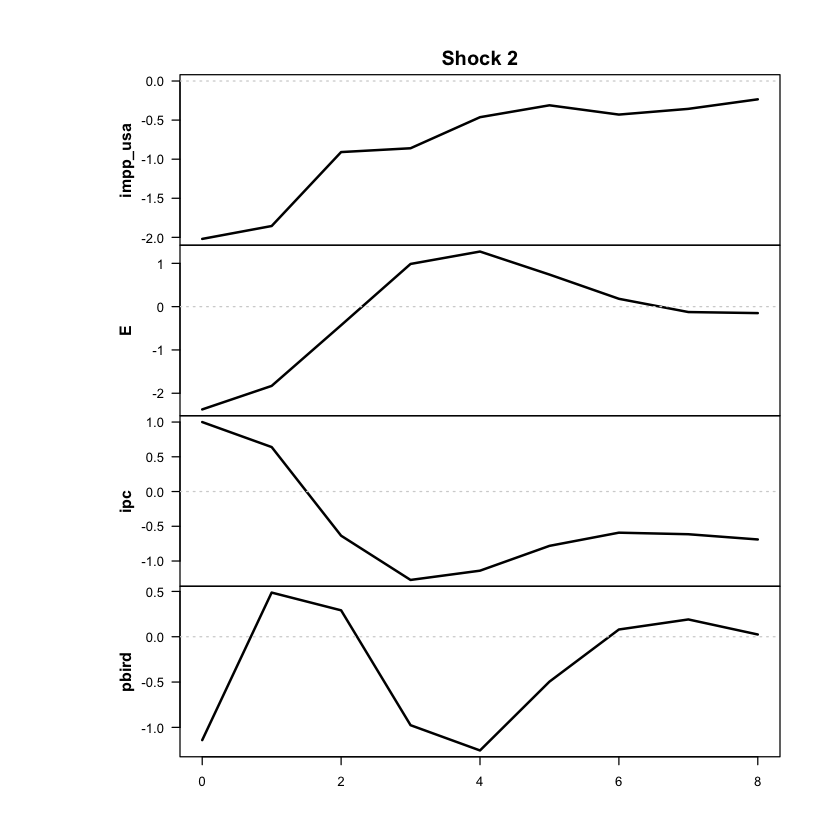

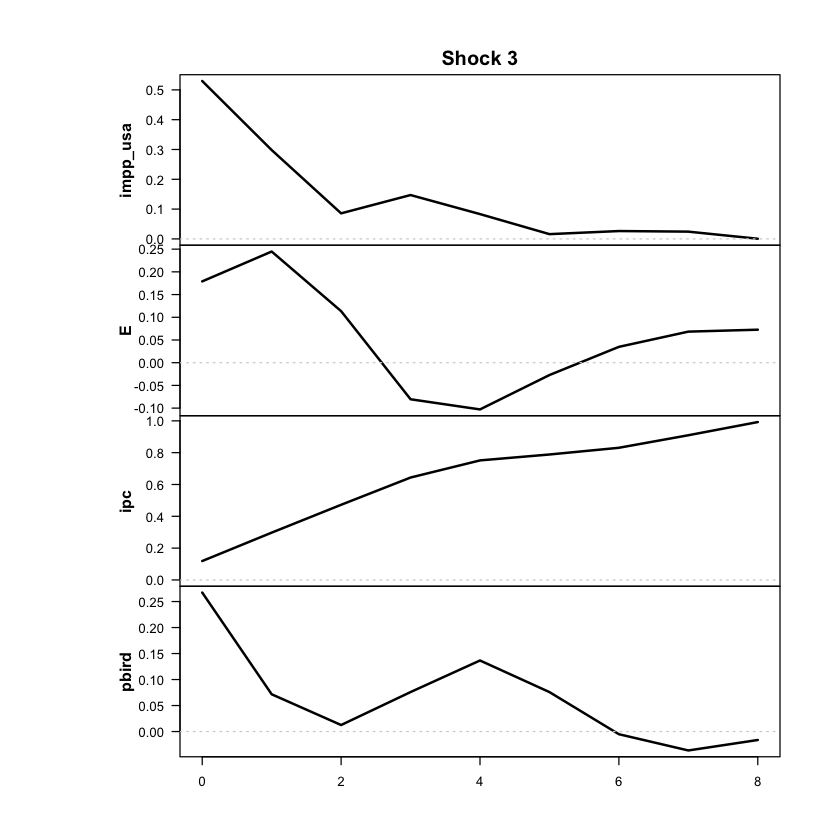

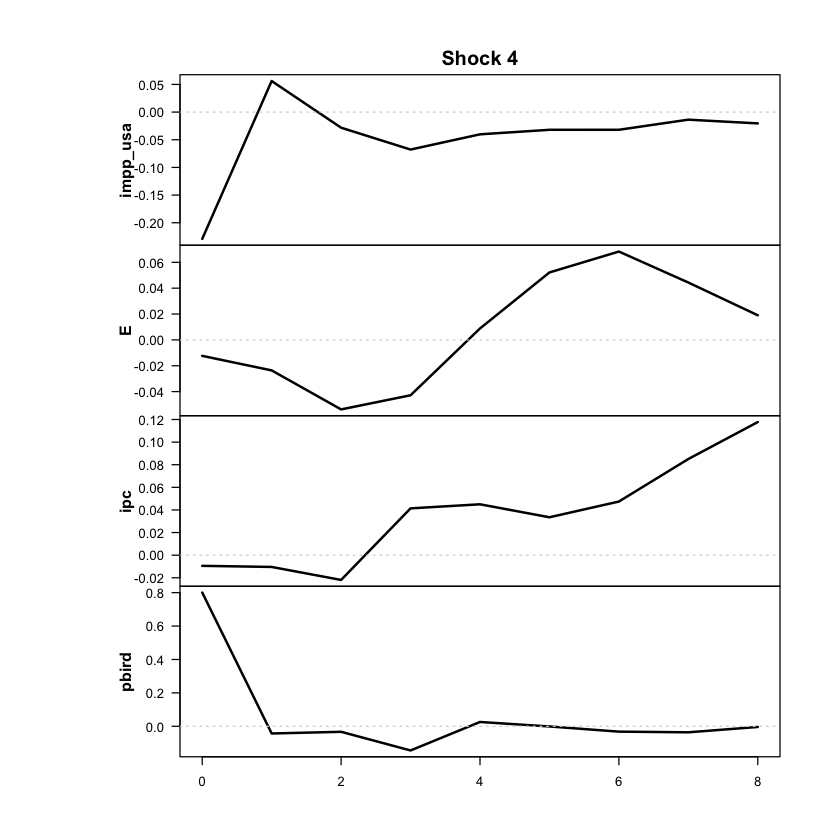

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



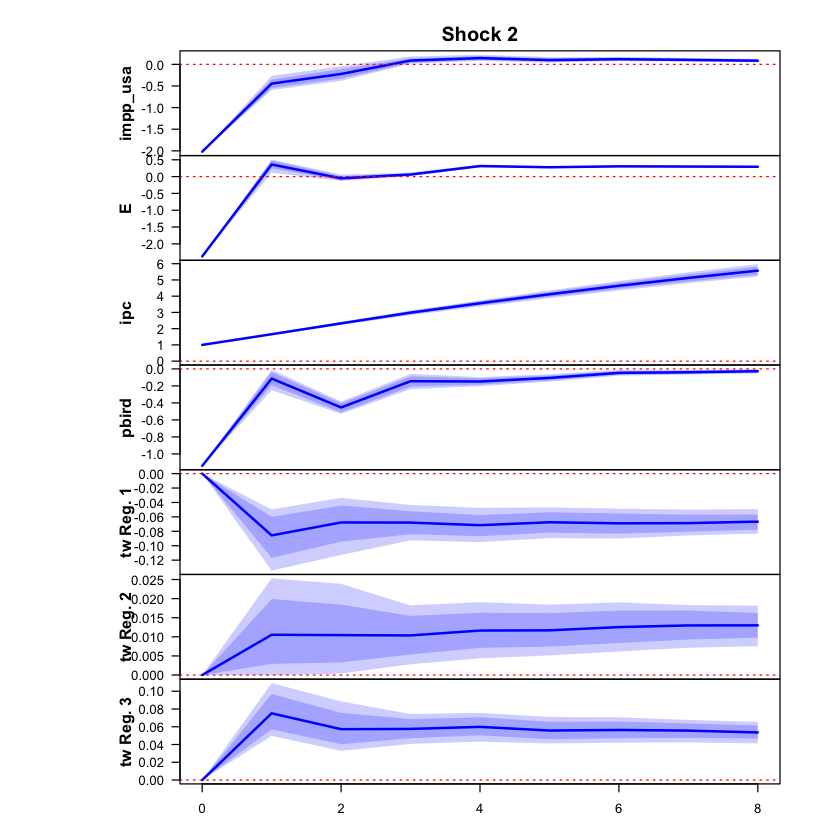

 >>> Linear IRF ( 1  shock units)


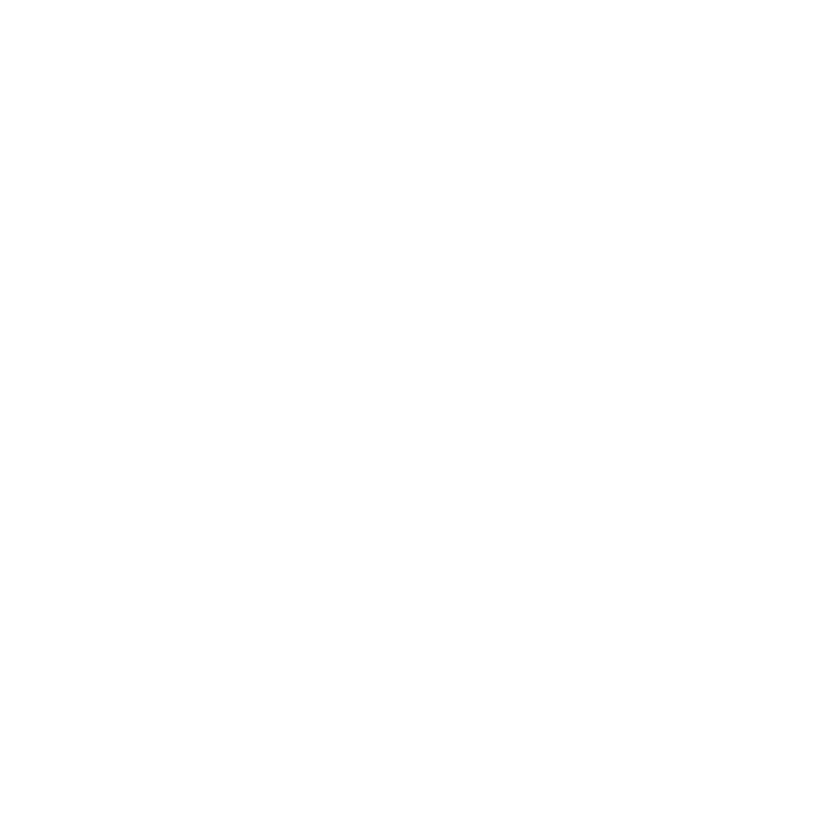

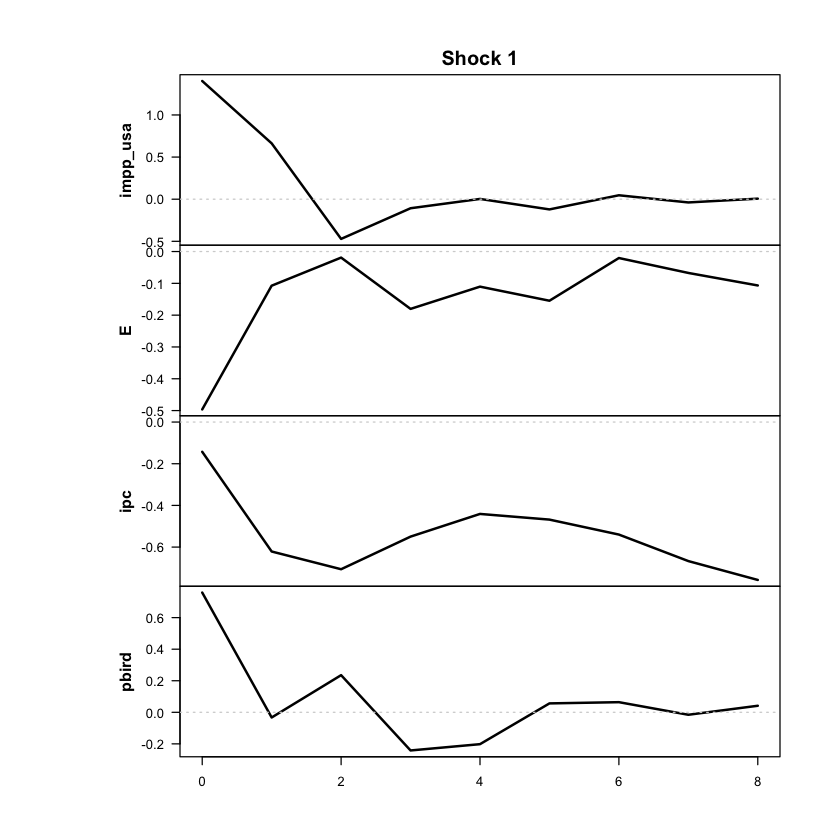

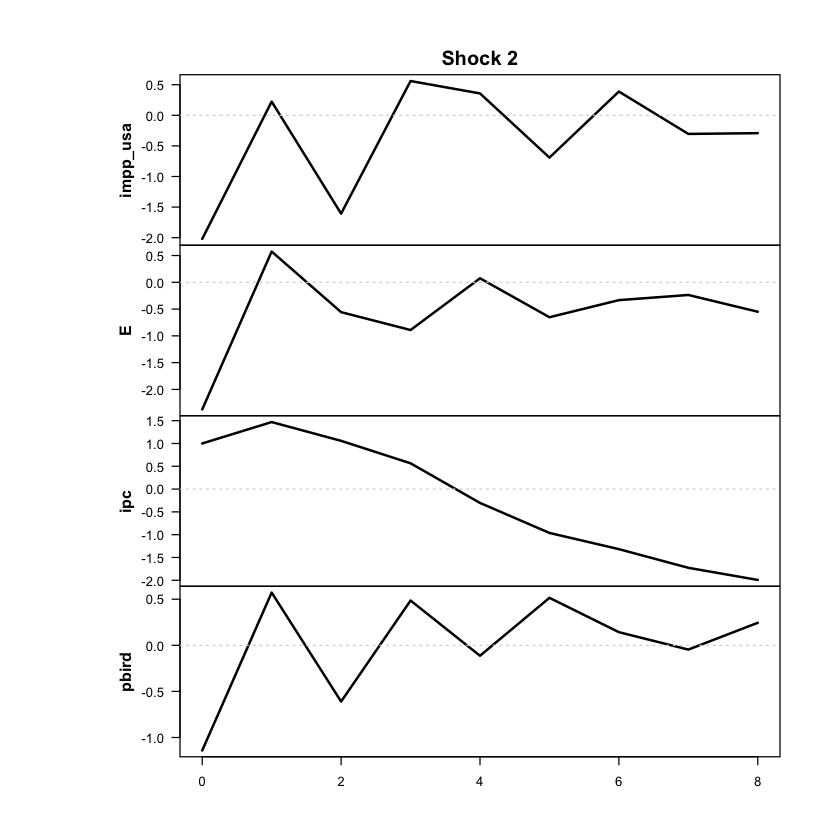

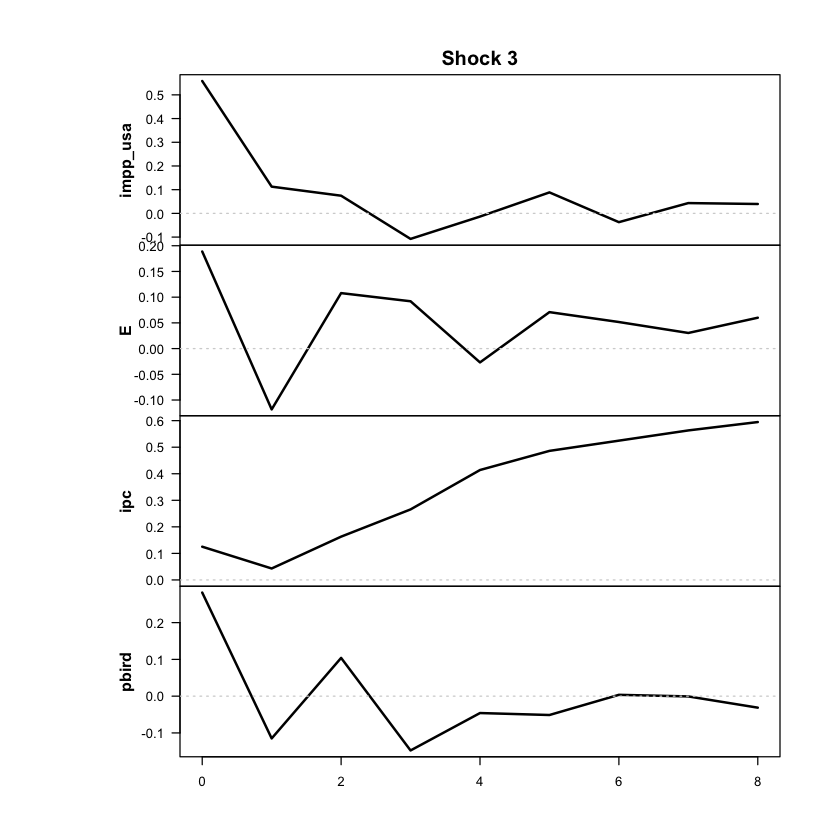

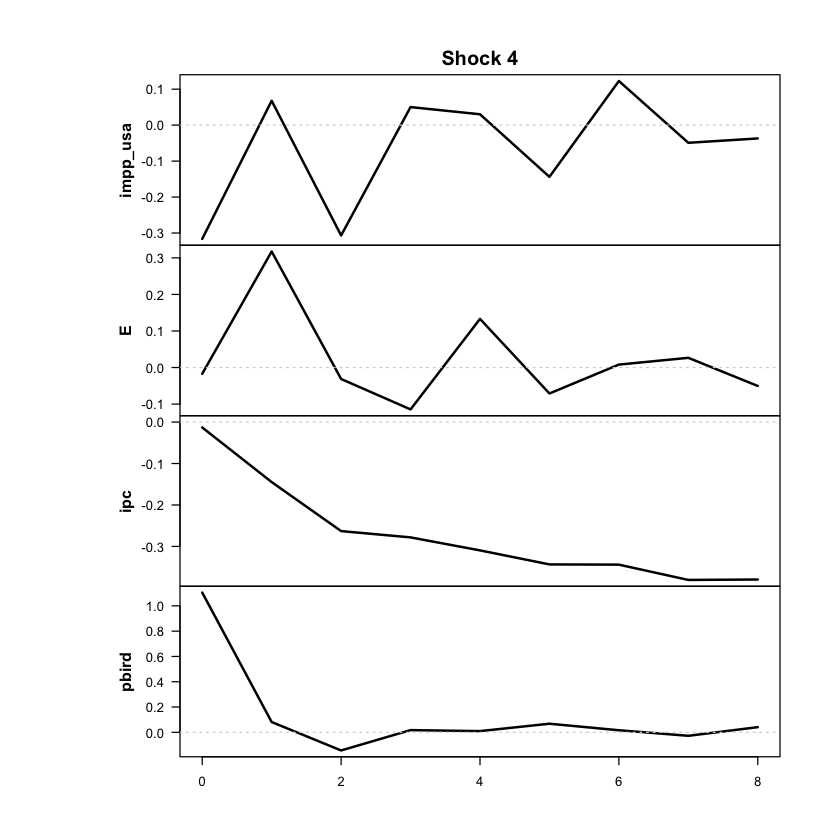

+++++++++ RÉGIMEN  3 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



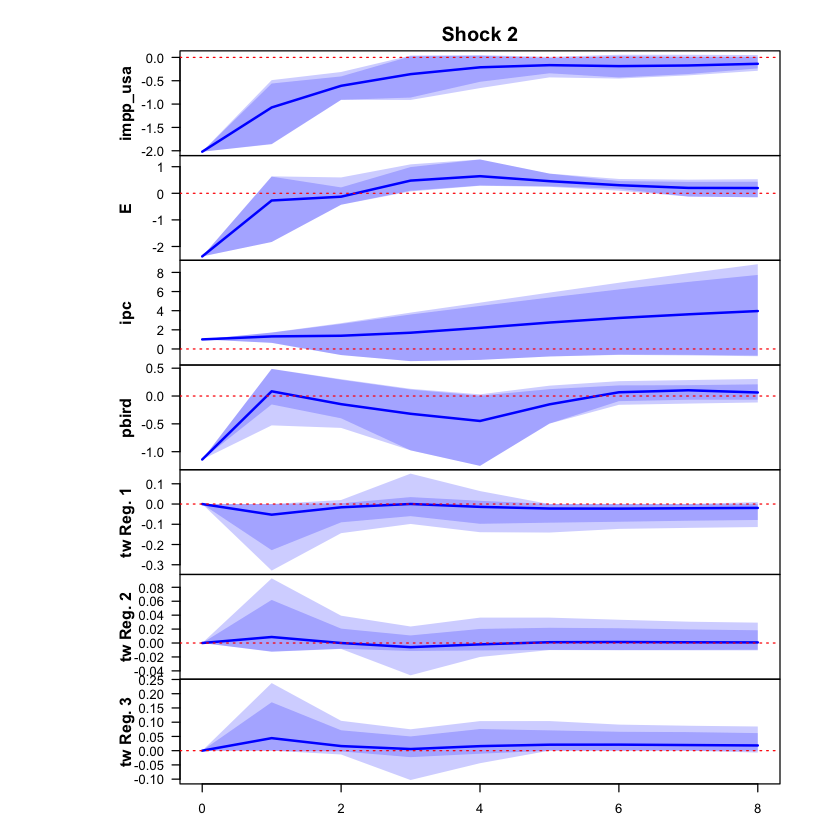

 >>> Linear IRF ( 1  shock units)


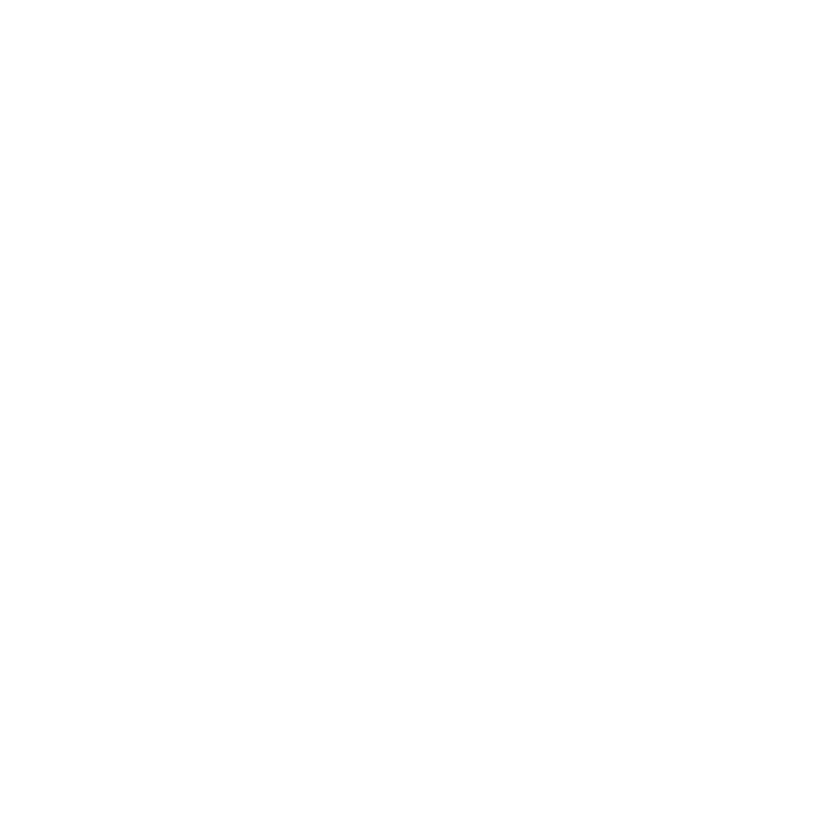

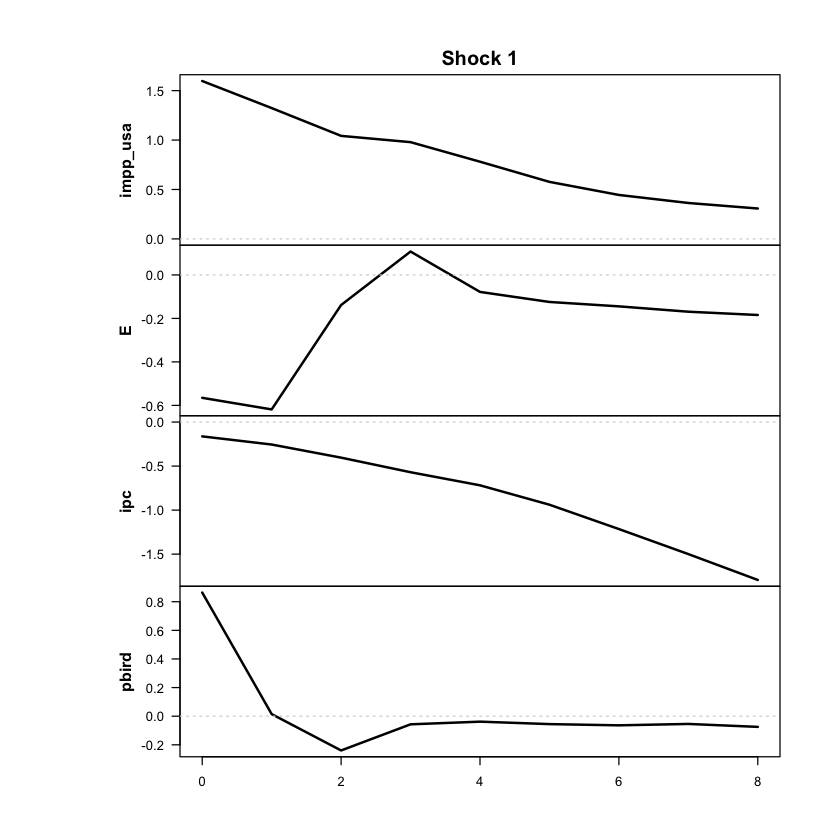

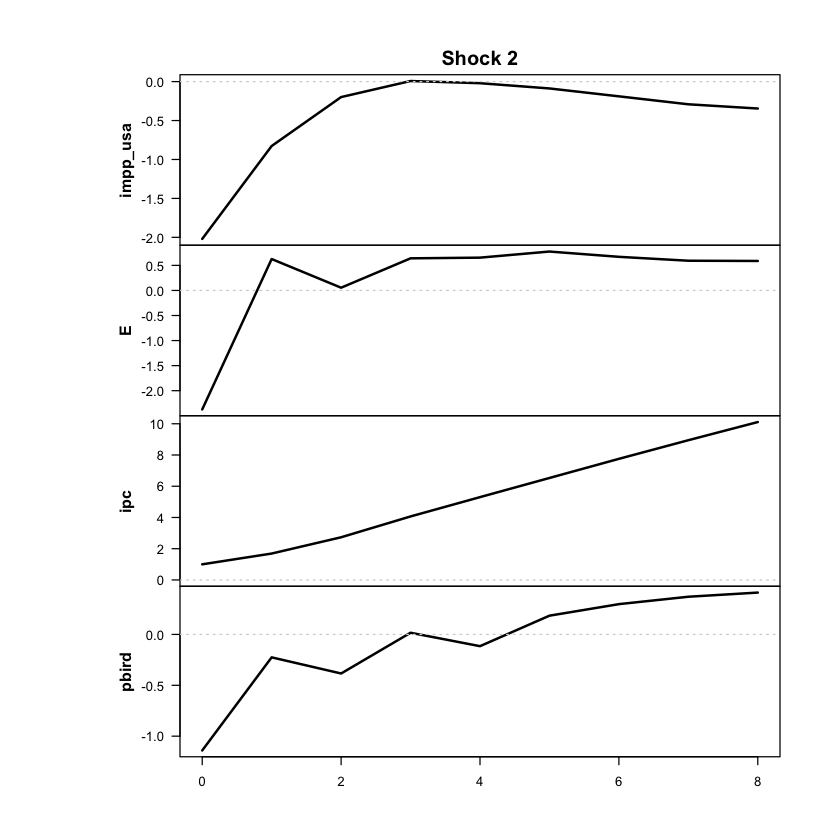

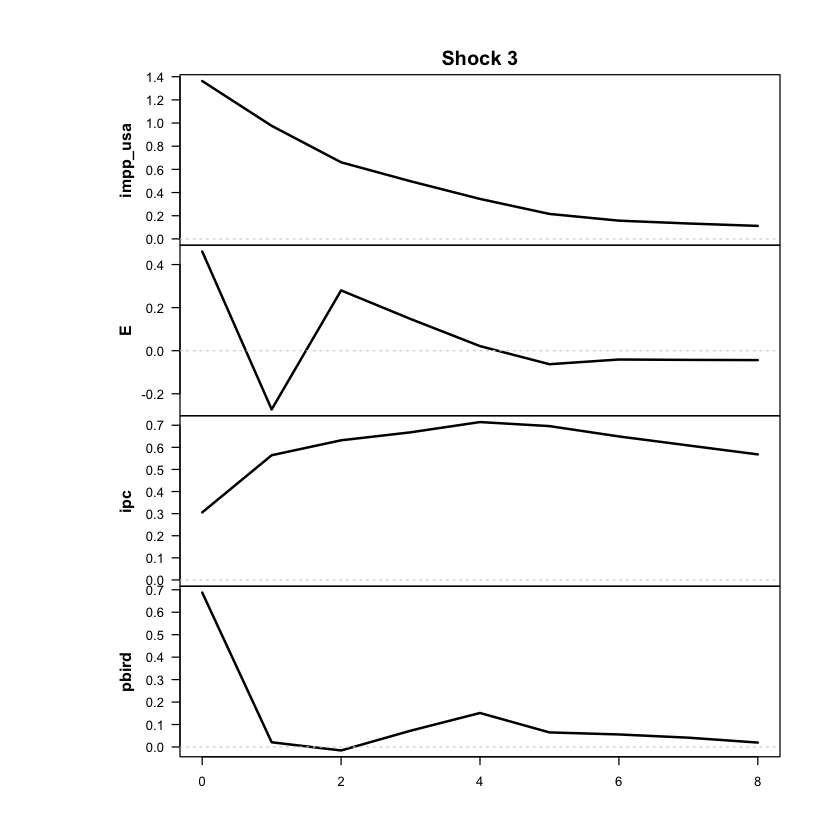

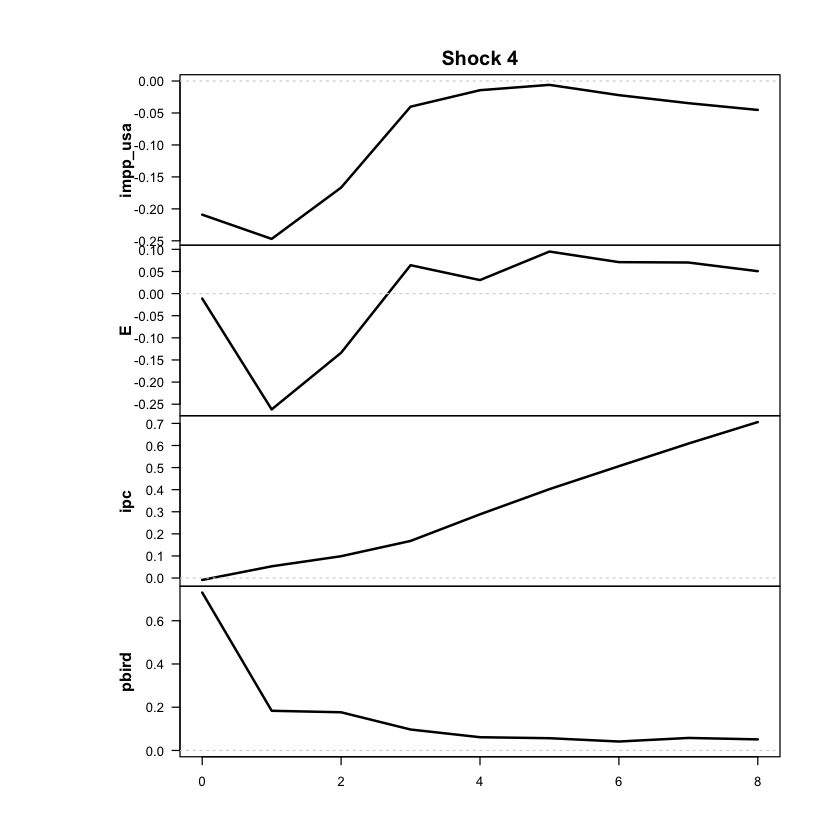

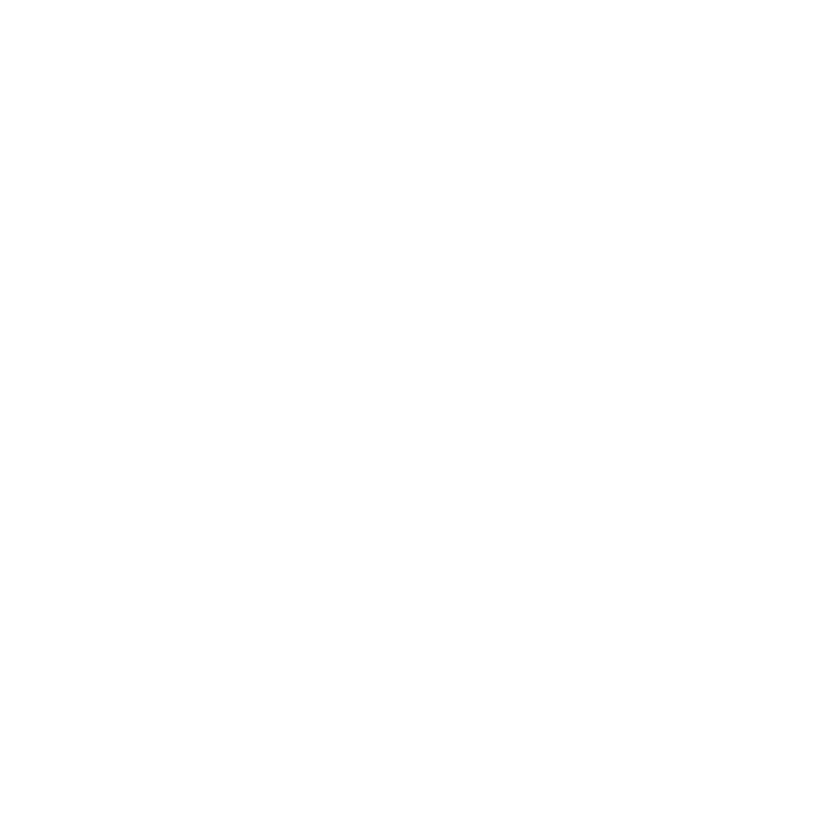

In [9]:
res <- run_mlogit(
  data = df_ERPT_Arg_capped,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral',
  feature_lag = 3,
  n_regimes = 3,
  cumulative = TRUE,
  thr_var = 'ipc',
  thr_lag = 1,
  shock_var = 'E',
  response_vars = c('ipc'),
  run_tests = FALSE,
  irf_horizons = NULL,
  irf_shocks = 1,
  diagnostic_plots = TRUE,
  nrounds = 500,
  load_presaved = FALSE
)

In [10]:
ic_mlogit3_p3_cap <- criterios_info(res, "MLOGIT 3 reg p=3 cap")
print(ic_mlogit3_p3_cap)

                modelo regimenes parametros   loglik    AIC     HQ    BIC
1 MLOGIT 3 reg p=3 cap         3        190 -1090.96 2561.9 2841.7 3260.5


In [11]:
resumen_modelo(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"))
# Mirar: dos cambios de régimen dominante, ordenados, y si se parecen a 2,5% y 12,5%.

Modelo: mlogit | regímenes: 3 | rezagos: 3 | errores: Gaussian 
Transición mlogit (parámetros gamma, escalados): 1.538, -1.427, -0.764, -0.071 
Cambios de régimen dominante según la inflación de t-1:
 de_regimen a_regimen inflacion_trim_pct inflacion_anual_pct
          1         3               13.7                  67
Trimestres por régimen (régimen de mayor peso): régimen 1 = 212 | régimen 2 = 0 | régimen 3 = 80 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2 Régimen 3
impp_usa      0.55       NaN      1.04
E             4.06       NaN     28.52
ipc           5.15       NaN     30.48
pbird         0.79       NaN      0.01


In [12]:
explorar_optimos(res, n = 20)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest   loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -1006.95              NA    NA         NA        182/25/85
             2 -1008.96              NA    NA         NA         203/0/89
             3 -1012.73              NA    NA         NA         201/0/91
             4 -1012.75              NA    NA         NA         207/0/85
             5 -1014.77              NA    NA         NA         82/210/0
             6 -1019.05              NA    NA         NA         0/207/85
             7 -1020.08              NA    NA         NA         216/76/0
             8 -1025.65              NA    NA         NA        16/208/68
          

In [13]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

mlogit Gaussian STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 3, M = 3, d = 4, #parameters = 190, #observations = 292 x 4
  Switching variables: ipc with 1 lag.

Regime 1 
Weight params:  1.54, -1.43 
Regime means: -0.11,  0.42,  0.36,  0.44

   Y      phi0          A1                                 A2                  
1 y1 = [ -0.08 ] + [  0.37  0.34 -0.08  0.18 ] y1.1 + [ -0.01 -0.24 -0.36 -0.05
2 y2   [  0.16 ]   [  0.09  0.85  0.37  0.01 ] y2.1   [ -0.13 -0.47 -0.07 -0.09
3 y3   [ -0.08 ]   [  0.10  0.29  0.56  0.04 ] y3.1   [ -0.05  0.14 -0.18 -0.02
4 y4   [  0.61 ]   [  0.19 -0.29  0.18  0.00 ] y4.1   [  0.01 -0.02  0.08 -0.06
                A3                              Omega                     1/2
1 ] y1.2 + [  0.33  0.17  0.03  0.04 ] y1.3 + [  0.39  0.11  0.05 -0.12 ]    
2 ] y2.2   [ -0.13 -0.12  0.22 -0.03 ] y2.3   [  0.11  0.07  0.01  0.01 ]    
3 ] y3.2   [ -0.01 -0.08  0.30  0.12 ] y3.3   [  0.05  0.01  0.02 -0.01 ]    
4 ] y4.2   

In [14]:
shock_mlogit3_p3_cap <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_mlogit3_p3_cap <- 2
shock_mlogit3_p3_cap

Efecto de impacto de cada shock (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0038  0.0029  0.0103 -0.0045
  E        -0.0105  0.0266  0.0274 -0.0019
  ipc      -0.0024 -0.0089  0.0144 -0.0011
  pbird     0.0025  0.0020  0.0063  0.0188

Participación de E en el efecto de cada shock:
shock_1 shock_2 shock_3 shock_4 
   0.30    0.68    0.28    0.01 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.229  -0.335   0.528   0.608 

>>> Shock sugerido como cambiario: 2 (confirmalo: debe mover mucho a E y poco a ipc )


Shock 2 
      2

### ERPT — mlogit p = 3 (solo si pasó el diagnóstico)

In [15]:
out_impp_usa_mlogit3_p3_cap <- erpt_historia(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_mlogit3_p3_cap)

Estimando 292 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 0 | régimen 2 = 0 | régimen 3 = 0 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.7952

  horizonte reg_1_original reg_2_original reg_3_original
1         0            NaN            NaN            NaN
2         1            NaN            NaN            NaN
3         2            NaN            NaN            NaN
4         3            NaN            NaN            NaN
5         4            NaN            NaN            NaN
6         5            NaN            NaN            NaN
7         6            NaN            NaN            NaN
8         7            NaN            NaN            NaN
9         8            NaN            NaN            NaN


In [16]:
out_impp_usa_mlogit3_p3_cap_acum <- erpt_historia(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_mlogit3_p3_cap,
                      definicion = "acumulado")

Estimando 292 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 0 | régimen 2 = 0 | régimen 3 = 0 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.7952

  horizonte reg_1_original reg_2_original reg_3_original
1         0            NaN            NaN            NaN
2         1            NaN            NaN            NaN
3         2            NaN            NaN            NaN
4         3            NaN            NaN            NaN
5         4            NaN            NaN            NaN
6         5            NaN            NaN            NaN
7         6            NaN            NaN            NaN
8         7            NaN            NaN            NaN
9         8            NaN            NaN            NaN


In [ ]:
graficar_transicion(res, data = df_ERPT_Arg_capped, endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_mlogit3_p3_cap")

## Comparación de criterios

Para comparar con los TVAR de 3 regímenes con cappeo, agregar a mano sus valores (TVAR 3 reg p=2 cap: loglik −972,88, AIC 2225,8, HQ 2432,1, BIC 2741,0; p=3: −931,19, 2238,4, 2515,3, 2929,6).

In [17]:
rbind(ic_mlogit3_p2_cap, ic_mlogit3_p3_cap)   # si no corriste p = 3, dejá solo ic_mlogit3_p2_cap

modelo,regimenes,parametros,loglik,AIC,HQ,BIC
<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
MLOGIT 3 reg p=2 cap,3,142,-1163.50,2611.0,2820.3,3133.6
MLOGIT 3 reg p=3 cap,3,190,-1090.96,2561.9,2841.7,3260.5


# Test de Portmanteau (todos los modelos con cappeo e impp_usa, incluidos los de la otra notebook)

In [18]:
portmanteau_guardados <- function(data, rezagos_test = c(8, 12), carpeta = "models") {
  archivos <- list.files(carpeta, pattern = "\\.rds$", full.names = TRUE)
  archivos <- archivos[!grepl("^structured_", basename(archivos))]
  pval <- function(t) {
    nm <- grep("p_val|pval|p.val", names(t), value = TRUE)
    if (length(nm)) as.numeric(t[[nm[1]]]) else NA
  }
  etiqueta <- function(m) {
    wf <- m$model$weight_function
    tipo <- switch(if (is.null(wf)) "" else wf,
                   threshold = "TVAR", logistic = "VLSTAR", mlogit = "MLOGIT", "?")
    cd <- m$model$cond_dist
    if (!is.null(cd) && cd != "Gaussian") tipo <- paste0(tipo, "-t")
    tipo
  }
  filas <- list()
  for (f in archivos) {
    m <- tryCatch(readRDS(f), error = function(e) NULL)
    if (is.null(m) || is.null(m$data) || is.null(m$model)) next
    Y <- as.matrix(m$data); vars <- colnames(Y)
    if (!all(vars %in% names(data)) || nrow(data) != nrow(Y)) next
    X <- as.matrix(data[, vars]); X <- sweep(X, 2, apply(X, 2, sd, na.rm = TRUE), "/")
    if (!isTRUE(all.equal(unname(X), unname(Y), tolerance = 1e-6))) next
    for (L in rezagos_test) {
      ac <- tryCatch(Portmanteau_test(m, nlags = L, which_test = "autocorr"), error = function(e) NULL)
      hs <- tryCatch(Portmanteau_test(m, nlags = L, which_test = "het.sked"), error = function(e) NULL)
      filas[[length(filas) + 1]] <- data.frame(
        commodity = vars[1],
        modelo    = etiqueta(m),
        regimenes = m$model$M, rezagos = m$model$p, rezagos_test = L,
        p_autocorr = round(if (is.null(ac)) NA else pval(ac), 3),
        p_heterosc = round(if (is.null(hs)) NA else pval(hs), 3))
    }
  }
  tab <- do.call(rbind, filas)
  tab <- tab[order(tab$commodity, tab$modelo, tab$regimenes, tab$rezagos, tab$rezagos_test), ]
  print(tab, row.names = FALSE)
  invisible(tab)
}

# Solo los modelos con impp_usa (los viejos de commodities quedan afuera)
port_cap <- portmanteau_guardados(df_ERPT_Arg_capped)
port_impp_cap <- port_cap[port_cap$commodity == "impp_usa", ]
print(port_impp_cap, row.names = FALSE)

 commodity modelo regimenes rezagos rezagos_test p_autocorr p_heterosc
  impp_usa MLOGIT         3       2            8      0.000      0.000
  impp_usa MLOGIT         3       2           12      0.000      0.000
  impp_usa MLOGIT         3       3            8      0.000      0.000
  impp_usa MLOGIT         3       3           12      0.000      0.000
  impp_usa   TVAR         2       1            8      0.001      0.000
  impp_usa   TVAR         2       1           12      0.008      0.000
  impp_usa   TVAR         2       2            8      0.001      0.000
  impp_usa   TVAR         2       2           12      0.025      0.000
  impp_usa   TVAR         2       3            8      0.002      0.000
  impp_usa   TVAR         2       3           12      0.070      0.000
  impp_usa   TVAR         3       2            8      0.001      0.002
  impp_usa   TVAR         3       2           12      0.027      0.004
  impp_usa   TVAR         3       3            8      0.001      0.001
  impp